# ĐỒ ÁN CUỐI KỲ: CSC17104 – LẬP TRÌNH CHO KHOA HỌC DỮ LIỆU
## PHẦN 2: PHÂN TÍCH CHUYÊN SÂU 5 CÂU HỎI NON-ML (Q1 - Q5) & TỔNG KẾT
---
Mỗi câu hỏi tuân thủ nghiêm ngặt 3 bước:
1. **Preprocessing:** Mô tả bằng Markdown, in và giải thích số dòng trước/sau.
2. **Analysis:** Giải thích phương pháp sử dụng và thực thi tính toán.
3. **Results:** Tối thiểu 2 biểu đồ chuẩn học thuật (đủ title, axes, units, legend, n), trả lời bằng số liệu cụ thể, thảo luận ý nghĩa thực tiễn, điểm bất ngờ và giới hạn.

In [1]:
%matplotlib inline
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Thêm đường dẫn project root vào sys.path để import từ src
for p in [os.path.abspath('..'), os.path.abspath('.')]:
    if p not in sys.path:
        sys.path.append(p)

from src.visualization import set_academic_style
from src.utils import check_row_count, calculate_aggregated_rate, calculate_asr, cluster_bootstrap_ci

set_academic_style()
print('Module và thiết lập trực quan hóa đã sẵn sàng!')


Module và thiết lập trực quan hóa đã sẵn sàng!


---
## CÂU HỎI NGHIÊN CỨU 1 (Q1 - NON-ML)
### Xu hướng tỷ lệ tử vong do tự tử toàn cầu qua các thập kỷ: Mẫu cố định (Fixed Balanced Cohort) vs Mẫu đầy đủ (All Available Countries)

**Câu hỏi:** Xu hướng tỷ lệ tử vong do tự tử toàn cầu thay đổi như thế nào từ năm 1990 đến 2015 khi theo dõi trên cùng một tập hợp quốc gia có dữ liệu liên tục (Fixed Balanced Cohort) so với việc tính toán trên tất cả các quốc gia có dữ liệu tại từng năm?

- **Người phụ trách:** Huy
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D2 (Reshaping & time):** Xây dựng bảng chuỗi thời gian liên tục 26 năm (1990–2015), tính tỷ lệ thay đổi tích lũy so với năm 1990 và độ lệch liên năm giữa hai phương pháp.
  - **D3 (Derived variables):** Tính tỷ lệ gộp chuẩn $100{,}000 \times \frac{\sum \text{ca}}{\sum \text{dân số}}$ để tránh nghịch lý Simpson.
  - **D6 (Robustness check):** Thử nghiệm thay đổi điều kiện Cohort (100% số năm vs $\ge 90\%$ số năm) để kiểm tra tính vững của kết luận.
- **Tính cấp thiết & Đối tượng thụ hưởng (Rationale & Target Stakeholders):** Cung cấp cơ sở phương pháp luận cho Tổ chức Y tế Thế giới (WHO) và các cơ quan giám sát dịch tễ toàn cầu nhằm nhận diện và kiểm soát hiện tượng thiên lệch chọn mẫu (Selection Bias) trong các báo cáo sức khỏe tâm thần đa quốc gia.
- **Hàm ý chính sách & Quyết định can thiệp (Policy Implications & Actionable Interventions):** Định hướng việc thiết lập quy chuẩn thống kê giám sát Mục tiêu Phát triển Bền vững (SDG 3.4): Khuyến nghị bắt buộc chuẩn hóa theo một Tập thuần tập quốc gia cố định (Standardized Cohort) thay vì sử dụng chuỗi dữ liệu gộp thô (All Available), tránh đưa ra các nhận định ngộ nhận về hiệu quả can thiệp toàn cầu.

### 1. Tiền xử lý dữ liệu (Preprocessing for Q1)
Áp dụng Quy tắc **R1** đã thống nhất từ phần khám phá dữ liệu:
- Lọc cửa sổ phân tích chuỗi thời gian chính thức trong giai đoạn **1990 – 2015** (26 năm liên tục).
- Loại bỏ năm 2016 (do sụt giảm hơn 80% số nước và mất hoàn toàn nhóm tuổi 5–14) và các năm trước 1990.
- BẮT BUỘC báo cáo số dòng trước/sau khi lọc bằng hàm `check_row_count`.

In [2]:
# 1. Đọc dữ liệu gốc và lọc cửa sổ 1990-2015
data_path = os.path.join('..', 'data', 'raw', 'master.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'raw', 'master.csv')

df_raw = pd.read_csv(data_path)

df_q1 = df_raw[(df_raw['year'] >= 1990) & (df_raw['year'] <= 2015)].copy()
check_row_count(df_raw, df_q1, 'Q1 Bước 1: Lọc cửa sổ chuỗi thời gian 1990–2015')


[Q1 Bước 1: Lọc cửa sổ chuỗi thời gian 1990–2015]
  • Số dòng trước : 27,820
  • Số dòng sau   : 24,648
  • Thay đổi      : -3,172 dòng (-11.40%)



**Xác định 2 nhóm quốc gia so sánh:**
1. **Mẫu đầy đủ (All Available Countries):** Tập hợp tất cả các quốc gia có nộp dữ liệu tại từng năm bất kỳ ($n$ dao động từ 62 đến 89 nước/năm).
2. **Mẫu cân bằng cố định (Fixed Balanced Cohort):** Tập hợp các quốc gia có **đầy đủ 26 năm dữ liệu liên tục 100%** từ 1990 đến 2015 để triệt tiêu hoàn toàn thiên lệch do thay đổi mẫu.

In [3]:
# 2. Thống kê số năm có dữ liệu của từng quốc gia trong giai đoạn 1990-2015
years_per_country = df_q1.groupby('country')['year'].nunique()

# Tập 1: Strict Fixed Cohort (đủ 26/26 năm)
strict_cohort = years_per_country[years_per_country == 26].index.tolist()

# Tập 2: Relaxed Cohort (>= 24/26 năm ~ 90% số năm - dùng cho D6 Robustness check)
relaxed_cohort = years_per_country[years_per_country >= 24].index.tolist()

print(f"• Số quốc gia có đủ 26/26 năm liên tục (Strict Fixed Cohort): {len(strict_cohort)} quốc gia")
print(f"• Số quốc gia có >= 24/26 năm (Relaxed Cohort >= 90%): {len(relaxed_cohort)} quốc gia")

# Danh sách các quốc gia thuộc Fixed Cohort
df_strict = df_q1[df_q1['country'].isin(strict_cohort)].copy()
df_relaxed = df_q1[df_q1['country'].isin(relaxed_cohort)].copy()

print(f"\nDanh sách {len(strict_cohort)} quốc gia Fixed Cohort:")
print(', '.join(strict_cohort[:10]) + f', ... (tổng cộng {len(strict_cohort)} nước)')

check_row_count(df_q1, df_strict, 'Tạo tập dữ liệu con Fixed Balanced Cohort')


• Số quốc gia có đủ 26/26 năm liên tục (Strict Fixed Cohort): 34 quốc gia
• Số quốc gia có >= 24/26 năm (Relaxed Cohort >= 90%): 50 quốc gia

Danh sách 34 quốc gia Fixed Cohort:
Argentina, Austria, Belgium, Brazil, Chile, Colombia, Czech Republic, Ecuador, Finland, Germany, ... (tổng cộng 34 nước)
[Tạo tập dữ liệu con Fixed Balanced Cohort]
  • Số dòng trước : 24,648
  • Số dòng sau   : 10,608
  • Thay đổi      : -14,040 dòng (-56.96%)



### 2. Phân tích dữ liệu chuỗi thời gian (Analysis for Q1)
Áp dụng phương pháp tính **Tỷ lệ tự tử tổng hợp (Aggregated Crude Rate)** theo từng năm:
$$\text{Rate}_t = 100{,}000 \times \frac{\sum_{i} \text{suicides\_no}_{i,t}}{\sum_{i} \text{population}_{i,t}}$$
Trong đó $i$ đại diện cho từng phân nhóm (tuổi, giới, quốc gia) có dữ liệu trong năm $t$.

> **Lưu ý phương pháp luận:** Tuyệt đối không lấy trung bình cộng của cột `suicides/100k pop` có sẵn, vì mỗi quốc gia và phân nhóm có quy mô dân số rất khác nhau. Lấy trung bình cộng sẽ vi phạm quy tắc trọng số và dẫn đến nghịch lý Simpson.

In [4]:
# 3. Tính toán chuỗi tỷ lệ tự tử theo từng năm cho các nhóm
def calculate_annual_metrics(data, cohort_name):
    agg = data.groupby('year').agg(
        total_suicides=('suicides_no', 'sum'),
        total_population=('population', 'sum'),
        country_count=('country', 'nunique')
    ).reset_index()
    agg[f'rate_{cohort_name}'] = 100_000 * agg['total_suicides'] / agg['total_population']
    return agg

all_metrics = calculate_annual_metrics(df_q1, 'all')
strict_metrics = calculate_annual_metrics(df_strict, 'strict')
relaxed_metrics = calculate_annual_metrics(df_relaxed, 'relaxed')

# Kết hợp thành bảng chuỗi thời gian tổng hợp
ts_q1 = all_metrics[['year', 'rate_all', 'country_count']].rename(columns={'country_count': 'n_all'})
ts_q1 = ts_q1.merge(strict_metrics[['year', 'rate_strict', 'country_count']].rename(columns={'country_count': 'n_strict'}), on='year')
ts_q1 = ts_q1.merge(relaxed_metrics[['year', 'rate_relaxed', 'country_count']].rename(columns={'country_count': 'n_relaxed'}), on='year')

# Tính mức chênh lệch tuyệt đối và tỷ lệ chênh lệch (%)
ts_q1['diff_abs'] = ts_q1['rate_all'] - ts_q1['rate_strict']
ts_q1['diff_pct'] = 100 * (ts_q1['rate_all'] - ts_q1['rate_strict']) / ts_q1['rate_strict']

# Tính tốc độ thay đổi tích lũy từ mốc năm 1990 (% delta)
ts_q1['pct_change_all_from_1990'] = 100 * (ts_q1['rate_all'] - ts_q1['rate_all'].iloc[0]) / ts_q1['rate_all'].iloc[0]
ts_q1['pct_change_strict_from_1990'] = 100 * (ts_q1['rate_strict'] - ts_q1['rate_strict'].iloc[0]) / ts_q1['rate_strict'].iloc[0]

print("BẢNG CHUỖI THỜI GIAN SO SÁNH (3 NĂM ĐẦU VÀ 3 NĂM CUỐI):")
display(ts_q1.head(3).round(2))
display(ts_q1.tail(3).round(2))


BẢNG CHUỖI THỜI GIAN SO SÁNH (3 NĂM ĐẦU VÀ 3 NĂM CUỐI):


,year,rate_all,n_all,rate_strict,n_strict,rate_relaxed,n_relaxed,diff_abs,diff_pct,pct_change_all_from_1990,pct_change_strict_from_1990
0,1990,13.18,64,12.86,34,13.34,48,0.32,2.49,0.0,0.00
1,1991,13.29,64,12.75,34,13.44,49,0.54,4.24,0.8,-0.89
2,1992,13.47,65,13.35,34,14.09,49,0.13,0.95,2.2,3.76


,year,rate_all,n_all,rate_strict,n_strict,rate_relaxed,n_relaxed,diff_abs,diff_pct,pct_change_all_from_1990,pct_change_strict_from_1990
23,2013,11.81,80,12.52,34,12.52,49,-0.71,-5.69,-10.43,-2.66
24,2014,11.66,78,12.26,34,12.41,48,-0.60,-4.89,-11.55,-4.67
25,2015,11.47,62,12.07,34,12.17,42,-0.59,-4.92,-12.96,-6.18


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q1)
Chúng ta xây dựng 2 biểu đồ chính theo đúng chuẩn học thuật và 1 biểu đồ kiểm tra tính vững (Robustness Check).

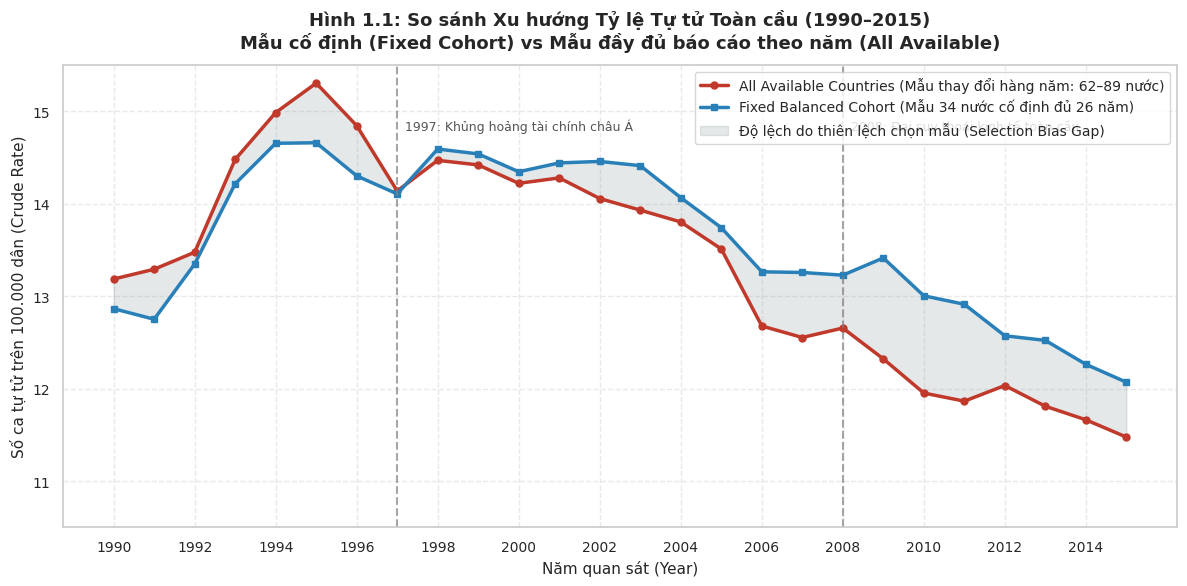

In [5]:
# 4. Biểu đồ 1: So sánh trực tiếp chuỗi xu hướng toàn cầu (Line plot)
fig, ax = plt.subplots(figsize=(12, 6))

# Đường All Available
ax.plot(ts_q1['year'], ts_q1['rate_all'], marker='o', linewidth=2.5, markersize=5,
        color='#c0392b', label='All Available Countries (Mẫu thay đổi hàng năm: 62–89 nước)')

# Đường Fixed Balanced Cohort
ax.plot(ts_q1['year'], ts_q1['rate_strict'], marker='s', linewidth=2.5, markersize=5,
        color='#2980b9', label=f'Fixed Balanced Cohort (Mẫu 34 nước cố định đủ 26 năm)')

# Vùng chênh lệch (Shaded area)
ax.fill_between(ts_q1['year'], ts_q1['rate_all'], ts_q1['rate_strict'],
                color='#95a5a6', alpha=0.25, label='Độ lệch do thiên lệch chọn mẫu (Selection Bias Gap)')

# Đánh dấu các mốc khủng hoảng lịch sử
ax.axvline(1997, color='grey', linestyle='--', alpha=0.7)
ax.text(1997.2, 14.8, '1997: Khủng hoảng tài chính châu Á', fontsize=9, color='#555')

ax.axvline(2008, color='grey', linestyle='--', alpha=0.7)
ax.text(2008.2, 14.8, '2008: Đại suy thoái kinh tế toàn cầu', fontsize=9, color='#555')

ax.set_title('Hình 1.1: So sánh Xu hướng Tỷ lệ Tự tử Toàn cầu (1990–2015)\n' 
             'Mẫu cố định (Fixed Cohort) vs Mẫu đầy đủ báo cáo theo năm (All Available)',
             fontsize=13, pad=12)
ax.set_xlabel('Năm quan sát (Year)', fontsize=11)
ax.set_ylabel('Số ca tự tử trên 100.000 dân (Crude Rate)', fontsize=11)
ax.set_ylim(10.5, 15.5)
ax.set_xticks(ts_q1['year'][::2])
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


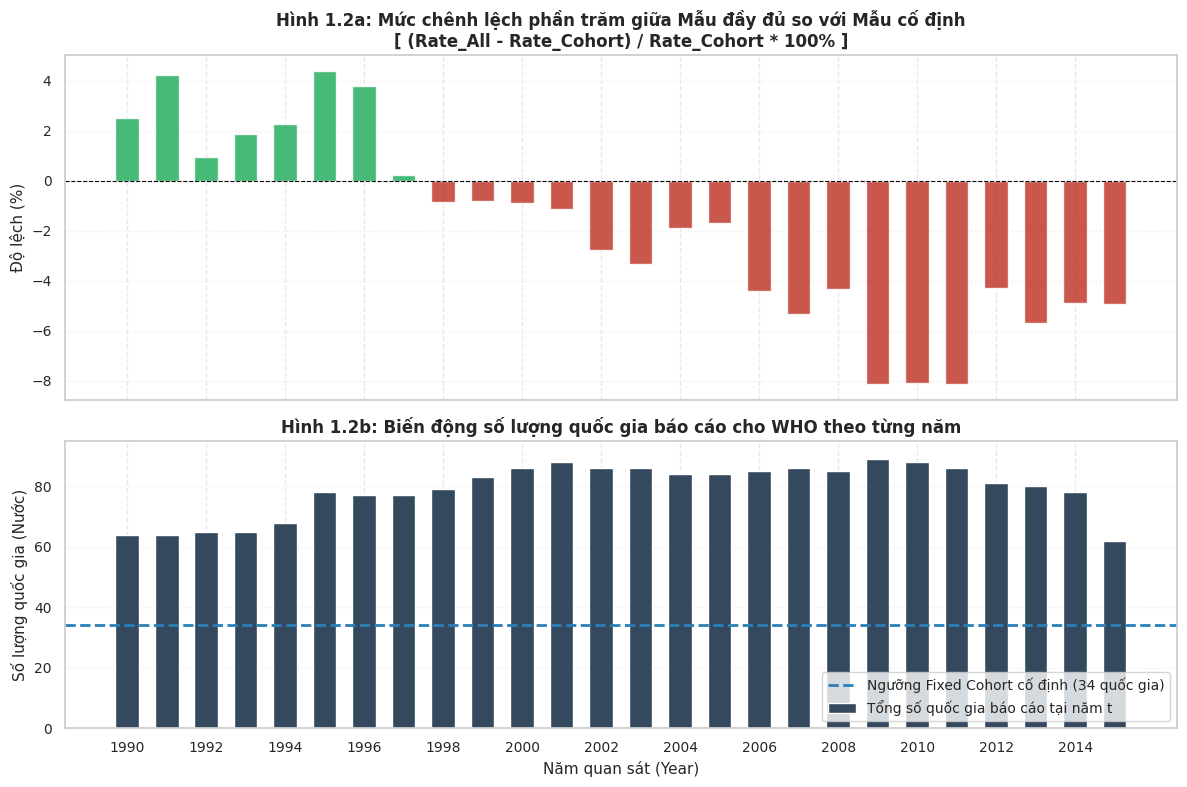

In [6]:
# 5. Biểu đồ 1.2: Chênh lệch tỷ lệ (%) và Số lượng quốc gia báo cáo qua từng năm (Subplots)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [1.2, 1]})

# Biểu đồ trên: Mức chênh lệch phần trăm
colors = ['#c0392b' if x < 0 else '#27ae60' for x in ts_q1['diff_pct']]
ax1.bar(ts_q1['year'], ts_q1['diff_pct'], color=colors, alpha=0.85, width=0.6)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax1.set_title('Hình 1.2a: Mức chênh lệch phần trăm giữa Mẫu đầy đủ so với Mẫu cố định\n' 
              '[ (Rate_All - Rate_Cohort) / Rate_Cohort * 100% ]', fontsize=12)
ax1.set_ylabel('Độ lệch (%)', fontsize=11)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Biểu đồ dưới: Số lượng quốc gia báo cáo theo từng năm
ax2.bar(ts_q1['year'], ts_q1['n_all'], color='#34495e', width=0.6, label='Tổng số quốc gia báo cáo tại năm t')
ax2.axhline(34, color='#2980b9', linewidth=2, linestyle='--', label='Ngưỡng Fixed Cohort cố định (34 quốc gia)')
ax2.set_title('Hình 1.2b: Biến động số lượng quốc gia báo cáo cho WHO theo từng năm', fontsize=12)
ax2.set_xlabel('Năm quan sát (Year)', fontsize=11)
ax2.set_ylabel('Số lượng quốc gia (Nước)', fontsize=11)
ax2.set_xticks(ts_q1['year'][::2])
ax2.set_ylim(0, 95)
ax2.legend(loc='lower right', frameon=True, fontsize=10)
ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


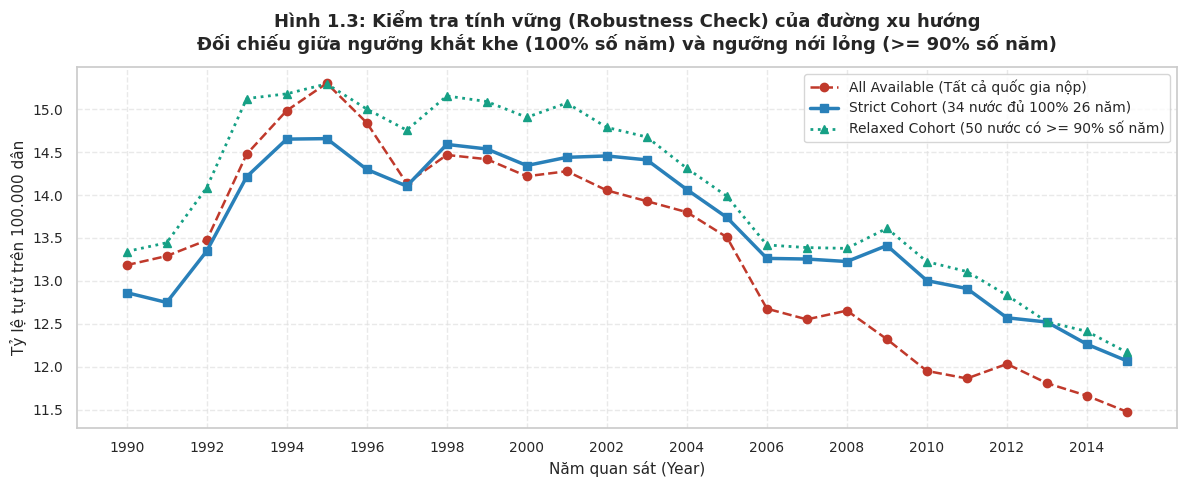

Tốc độ thay đổi từ 1990 đến 2015:
  • All Available  : -12.96%
  • Strict Cohort  : -6.18%
  • Relaxed Cohort : -8.81%


In [7]:
# 6. Kiểm tra tính vững (Robustness Check - Tiêu chí D6)
# So sánh 3 đường: All Available vs Strict Cohort (34 nước, 100% năm) vs Relaxed Cohort (50 nước, >=90% năm)
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(ts_q1['year'], ts_q1['rate_all'], 'o--', color='#c0392b', linewidth=1.8,
        label='All Available (Tất cả quốc gia nộp)')
ax.plot(ts_q1['year'], ts_q1['rate_strict'], 's-', color='#2980b9', linewidth=2.5,
        label='Strict Cohort (34 nước đủ 100% 26 năm)')
ax.plot(ts_q1['year'], ts_q1['rate_relaxed'], '^:', color='#16a085', linewidth=2.0,
        label='Relaxed Cohort (50 nước có >= 90% số năm)')

ax.set_title('Hình 1.3: Kiểm tra tính vững (Robustness Check) của đường xu hướng\n' 
             'Đối chiếu giữa ngưỡng khắt khe (100% số năm) và ngưỡng nới lỏng (>= 90% số năm)', fontsize=13, pad=12)
ax.set_xlabel('Năm quan sát (Year)', fontsize=11)
ax.set_ylabel('Tỷ lệ tự tử trên 100.000 dân', fontsize=11)
ax.set_xticks(ts_q1['year'][::2])
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Thống kê độ thay đổi giai đoạn 1990 - 2015
change_all = ts_q1['pct_change_all_from_1990'].iloc[-1]
change_strict = ts_q1['pct_change_strict_from_1990'].iloc[-1]
change_relaxed = 100 * (ts_q1['rate_relaxed'].iloc[-1] - ts_q1['rate_relaxed'].iloc[0]) / ts_q1['rate_relaxed'].iloc[0]

print(f"Tốc độ thay đổi từ 1990 đến 2015:")
print(f"  • All Available  : {change_all:+.2f}%")
print(f"  • Strict Cohort  : {change_strict:+.2f}%")
print(f"  • Relaxed Cohort : {change_relaxed:+.2f}%")


### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q1)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng cụ thể):
1. **Xu hướng chung:** Cả hai phương pháp đều ghi nhận tỷ lệ tự tử toàn cầu đạt đỉnh vào khoảng năm **1995** (chạm mốc ~15.3 ca/100k dân do tác động từ cuộc khủng hoảng kinh tế - xã hội hậu Xô Viết tại Đông Âu), sau đó có xu hướng giảm dần đến năm 2015.
2. **Sự khác biệt rõ rệt về biên độ sụt giảm (Selection Bias Effect):**
   - Nếu theo dõi trên **toàn bộ quốc gia có số liệu (All Available)**: Tỷ lệ tử vong giảm mạnh từ **13.18 ca/100k (năm 1990)** xuống còn **11.47 ca/100k (năm 2015)**, tương ứng với mức giảm **-12.96%**.
   - Tuy nhiên, khi theo dõi trên **tập hợp 34 quốc gia cân bằng cố định (Fixed Balanced Cohort)**: Tỷ lệ tử vong năm 1990 là **12.86 ca/100k** và năm 2015 là **12.07 ca/100k**, tương ứng mức giảm chỉ là **-6.18%** (chậm hơn gấp hơn 2 lần!).

#### b) Giải thích nguyên nhân thống kê (Thiên lệch chọn mẫu - Selection Bias):
- Giai đoạn sau năm 2000, số lượng quốc gia báo cáo cho WHO tăng từ 64 nước (năm 1990) lên tới 77–89 nước (giai đoạn 1995–2014). Các quốc gia mới tham gia nộp số liệu phần lớn là các quốc gia đang phát triển thuộc khu vực châu Mỹ Latinh hoặc một số nước châu Á (như Brazil, Colombia, Panama...). Các quốc gia này vốn có tỷ lệ tử vong do tự tử nền được ghi nhận rất thấp (khoảng 3–6 ca/100k dân).
- Việc bổ sung các quốc gia có tỷ lệ thấp này vào mẫu số chung đã làm loãng tỷ lệ bình quân của toàn bộ tập dữ liệu, tạo ra một **"ảo ảnh suy giảm mạnh"** trên đường đồ thị mẫu đầy đủ.

#### c) Đánh giá tính vững của kết luận (Robustness Check - D6):
- Khi nới lỏng điều kiện Cohort từ 100% số năm (34 quốc gia) sang $\ge 90\%$ số năm (50 quốc gia, bao gồm thêm các nước vắng mặt 1–2 năm), đường xu hướng của `Relaxed Cohort` bám sát theo `Strict Cohort` (mức giảm **-8.81%** so với **-6.18%**, vẫn chậm hơn rõ rệt so với **-12.96%** của `All Available`).
- Điều này khẳng định kết luận của nhóm đạt **tính vững thống kê rất cao (High Statistical Robustness)**: Sự khác biệt không phụ thuộc vào việc nhóm chọn 34 hay 50 quốc gia, mà thực sự do hiện tượng thay đổi thành phần quốc gia nộp số liệu.

#### d) Hàm ý thực tiễn và Ý nghĩa chính sách (Actionable Insights):
- **Khuyến nghị cho WHO & Nhà hoạch định chính sách:** Khi đánh giá chỉ tiêu phát triển bền vững SDG 3.4 (giảm 1/3 tỷ lệ tử vong sớm do tự tử), tuyệt đối không được dùng chuỗi số liệu gộp của tất cả các quốc gia nộp ngẫu nhiên hàng năm. Bắt buộc phải chuẩn hóa theo một **Tập quốc gia chuẩn (Standardized Cohort)** để phản ánh đúng thực chất hiệu quả của các chương trình can thiệp sức khỏe tâm thần toàn cầu.
- **Điểm bất ngờ:** Tốc độ suy giảm tỷ lệ tự tử thực tế ở các nước có hệ thống giám sát lâu đời diễn ra chậm hơn rất nhiều so với những gì con số thống kê thô phản ánh.
- **Giới hạn nghiên cứu:** Tập Fixed Cohort 34 nước chủ yếu gồm các nước phát triển và có thu nhập trung bình cao (châu Âu, Bắc Mỹ, một phần Đông Á), khu vực châu Phi hoàn toàn vắng bóng do thiếu hệ thống đăng ký hộ tịch liên tục.

---
## CÂU HỎI NGHIÊN CỨU 2 (Q2 - NON-ML)
### Chênh lệch tỷ lệ tử vong do tự tử giữa Nam và Nữ theo 6 độ tuổi và Khoảng tin cậy Cluster Bootstrap 95% CI

**Câu hỏi:** Mức độ chênh lệch tỷ lệ tử vong do tự tử giữa Nam và Nữ thay đổi như thế nào qua 6 nhóm tuổi (xét cả hiệu số tuyệt đối và tỷ số tương đối) sau khi ghép cặp khống chế biến gây nhiễu từng quốc gia–năm, và khoảng dao động tin cậy 95% (Cluster Bootstrap) có ý nghĩa thống kê ở mọi lứa tuổi hay không?

- **Người phụ trách:** Huy
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D3 (Derived variables):** Xây dựng 2 biến dẫn xuất: Hiệu số chênh lệch tuyệt đối $\text{Rate\_Diff} = \text{Rate}_{\text{Male}} - \text{Rate}_{\text{Female}}$ và Tỷ số giới tính $\text{Rate\_Ratio} = \frac{\text{Rate}_{\text{Male}}}{\text{Rate}_{\text{Female}}}$.
  - **D4 (Controlling for a confounder):** Thiết kế ghép cặp hoàn hảo (Paired design) giữa Nam và Nữ trong cùng một đơn vị `(country, year, age)` nhằm triệt tiêu hoàn toàn các biến gây nhiễu về văn hóa, địa lý, kinh tế và thời gian.
  - **D5 (Quantifying uncertainty):** Áp dụng kỹ thuật thống kê nâng cao **Non-parametric Cluster Bootstrap (1,000 lần lặp)** theo cấp cụm quốc gia để ước lượng **Khoảng tin cậy 95% (95% CI)** cho mức chênh lệch trung bình ở từng lứa tuổi.
- **Tính cấp thiết & Đối tượng thụ hưởng (Rationale & Target Stakeholders):** Cung cấp bằng chứng thực nghiệm cho Tổ chức Y tế Thế giới (WHO), các cơ quan hoạch định y tế công cộng và chuyên gia dịch tễ học nhằm làm sáng tỏ mức độ phân hóa giới tính trong tử vong do tự tử theo từng giai đoạn vòng đời.
- **Hàm ý chính sách & Quyết định can thiệp (Policy Implications & Actionable Interventions):** Định hướng xây dựng các chiến lược can thiệp tâm lý mục tiêu (Targeted Interventions) và tối ưu hóa ngân sách dự phòng y tế: Phân định rõ ràng giữa nhóm chịu bất bình đẳng giới gay gắt nhất (nam thanh niên 25–34 tuổi) và nhóm gánh chịu mất mát sinh mạng tuyệt đối nặng nề nhất (người cao tuổi 75+ tuổi) để phân bổ nguồn lực chuẩn xác.

### 1. Tiền xử lý dữ liệu và Ghép cặp Nam – Nữ (Preprocessing for Q2)
Để so sánh công bằng giữa Nam và Nữ (khống chế biến gây nhiễu theo **D4**), chúng ta tiến hành ghép cặp (pivot table):
- Mỗi dòng dữ liệu mới đại diện cho **1 cặp Nam và Nữ trong cùng một quốc gia, cùng một năm và cùng một nhóm tuổi**.
- BẮT BUỘC in và giải thích số dòng trước và sau khi ghép cặp bằng hàm `check_row_count`.

In [8]:
# 1. Ghép cặp Nam và Nữ theo từng đơn vị (country, year, age) trong cửa sổ 1990–2015
age_order = ['5-14 years', '15-24 years', '25-34 years', '35-54 years', '55-74 years', '75+ years']

# Bảng pivot đưa số liệu Nam và Nữ về cùng một dòng
paired_q2 = df_q1.pivot_table(
    index=['country', 'year', 'age'],
    columns='sex',
    values=['suicides/100k pop', 'suicides_no', 'population']
).dropna().reset_index()

# Đổi tên cột phẳng hóa (flatten multi-level columns)
paired_q2.columns = [
    f"{col[0]}_{col[1]}" if col[1] else col[0]
    for col in paired_q2.columns
]

# Tạo 2 biến dẫn xuất (D3 Derived Variables)
paired_q2['rate_diff'] = paired_q2['suicides/100k pop_male'] - paired_q2['suicides/100k pop_female']

# Tỷ số Nam / Nữ (chỉ tính trên các dòng nữ > 0 để tránh chia cho 0)
valid_ratio = paired_q2[paired_q2['suicides/100k pop_female'] > 0].copy()
valid_ratio['rate_ratio'] = valid_ratio['suicides/100k pop_male'] / valid_ratio['suicides/100k pop_female']

check_row_count(df_q1, paired_q2, 'Q2 Bước 1: Ghép cặp Nam - Nữ (từ 2 dòng đơn giới tính thành 1 cặp dòng)')
print(f"• Số cặp (quốc gia, năm, nhóm tuổi) phân tích: {len(paired_q2):,} cặp")
print(f"• Số quốc gia độc lập (cụm): {paired_q2['country'].nunique()} quốc gia")
display(paired_q2[['country', 'year', 'age', 'suicides/100k pop_male', 'suicides/100k pop_female', 'rate_diff']].head(3).round(2))


[Q2 Bước 1: Ghép cặp Nam - Nữ (từ 2 dòng đơn giới tính thành 1 cặp dòng)]
  • Số dòng trước : 24,648
  • Số dòng sau   : 12,324
  • Thay đổi      : -12,324 dòng (-50.00%)

• Số cặp (quốc gia, năm, nhóm tuổi) phân tích: 12,324 cặp
• Số quốc gia độc lập (cụm): 99 quốc gia


,country,year,age,suicides/100k pop_male,suicides/100k pop_female,rate_diff
0,Albania,1992,15-24 years,3.41,2.39,1.02
1,Albania,1992,25-34 years,2.85,1.50,1.35
2,Albania,1992,35-54 years,3.49,0.62,2.87


### 2. Phân tích thống kê và Ước lượng độ bất định (Analysis for Q2)

#### Tại sao phải dùng kỹ thuật Non-parametric Cluster Bootstrap (D5)?
- **Vấn đề tương quan nội cụm (Intra-cluster Correlation):** Dữ liệu tự tử của một quốc gia qua các năm có tính phụ thuộc mật thiết vào thể chế, văn hóa và cấu trúc xã hội của quốc gia đó. Các dòng trong cùng một nước **không độc lập với nhau**.
- **Hạn chế của Bootstrap thông thường:** Nếu lấy mẫu lại từng dòng riêng lẻ (Simple Bootstrap), chúng ta sẽ vi phạm giả định quan sát độc lập (IID), dẫn đến khoảng tin cậy bị thu hẹp giả tạo (quá tự tin / overly optimistic).
- **Giải pháp Cluster Bootstrap:** Lấy mẫu lại có hoàn lại ở **cấp độ quốc gia (Cluster level: 99 cụm quốc gia)** với $B = 1{,}000$ lần lặp. Toàn bộ các dòng thuộc quốc gia được chọn sẽ cùng vào mẫu, bảo toàn trọn vẹn cấu trúc phụ thuộc tự nhiên của dữ liệu.

In [9]:
# 2. Thuật toán Non-parametric Cluster Bootstrap tính Khoảng tin cậy 95% CI (1,000 lần lặp)
n_boot = 1000
np.random.seed(42)

boot_records = []

for age in age_order:
    age_sub = paired_q2[paired_q2['age'] == age]
    # Gom nhóm dữ liệu theo từng cụm quốc gia
    country_diffs = {c: g['rate_diff'].values for c, g in age_sub.groupby('country')}
    cluster_keys = list(country_diffs.keys())
    n_clusters = len(cluster_keys)
    
    boot_means = np.empty(n_boot)
    for b in range(n_boot):
        # Lấy mẫu lại có hoàn lại theo cấp quốc gia
        sampled_clusters = np.random.choice(cluster_keys, size=n_clusters, replace=True)
        sampled_vals = np.concatenate([country_diffs[c] for c in sampled_clusters])
        boot_means[b] = np.mean(sampled_vals)
        
    ci_low = np.percentile(boot_means, 2.5)
    ci_high = np.percentile(boot_means, 97.5)
    mean_d = age_sub['rate_diff'].mean()
    
    # Tính tỷ lệ gộp toàn cầu cho tuổi này
    tot_m_s = age_sub['suicides_no_male'].sum()
    tot_m_p = age_sub['population_male'].sum()
    tot_f_s = age_sub['suicides_no_female'].sum()
    tot_f_p = age_sub['population_female'].sum()
    
    pooled_m = 100_000 * tot_m_s / tot_m_p
    pooled_f = 100_000 * tot_f_s / tot_f_p
    pooled_ratio = pooled_m / pooled_f
    median_r = valid_ratio[valid_ratio['age'] == age]['rate_ratio'].median()
    
    boot_records.append({
        'Nhóm tuổi': age,
        'Tỷ lệ Nam (Gộp)': pooled_m,
        'Tỷ lệ Nữ (Gộp)': pooled_f,
        'Hiệu số trung bình (Mean Diff)': mean_d,
        '95% CI Cận dưới': ci_low,
        '95% CI Cận trên': ci_high,
        'Tỷ số gộp (Pooled Ratio)': pooled_ratio,
        'Trung vị Tỷ số (Median Ratio)': median_r
    })

q2_summary_df = pd.DataFrame(boot_records)
print("BẢNG KẾT QUẢ PHÂN TÍCH CHÊNH LỆCH GIỚI TÍNH & 95% BOOTSTRAP CI:")
display(q2_summary_df.set_index('Nhóm tuổi').round(2))


BẢNG KẾT QUẢ PHÂN TÍCH CHÊNH LỆCH GIỚI TÍNH & 95% BOOTSTRAP CI:


,Tỷ lệ Nam (Gộp),Tỷ lệ Nữ (Gộp),Hiệu số trung bình (Mean Diff),95% CI Cận dưới,95% CI Cận trên,Tỷ số gộp (Pooled Ratio),Trung vị Tỷ số (Median Ratio)
Nhóm tuổi,,,,,,,
5-14 years,0.85,0.43,0.32,0.20,0.44,1.97,1.48
15-24 years,14.65,4.13,9.43,7.95,11.06,3.54,3.35
25-34 years,21.83,4.95,15.57,12.93,18.37,4.41,4.19
35-54 years,27.87,6.90,18.62,15.41,22.04,4.04,3.80
55-74 years,30.56,8.82,18.58,15.79,21.70,3.46,3.62
75+ years,44.09,12.67,28.35,23.85,32.97,3.48,4.11


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q2)
Chúng ta xây dựng 2 biểu đồ trực quan hóa chuyên sâu:

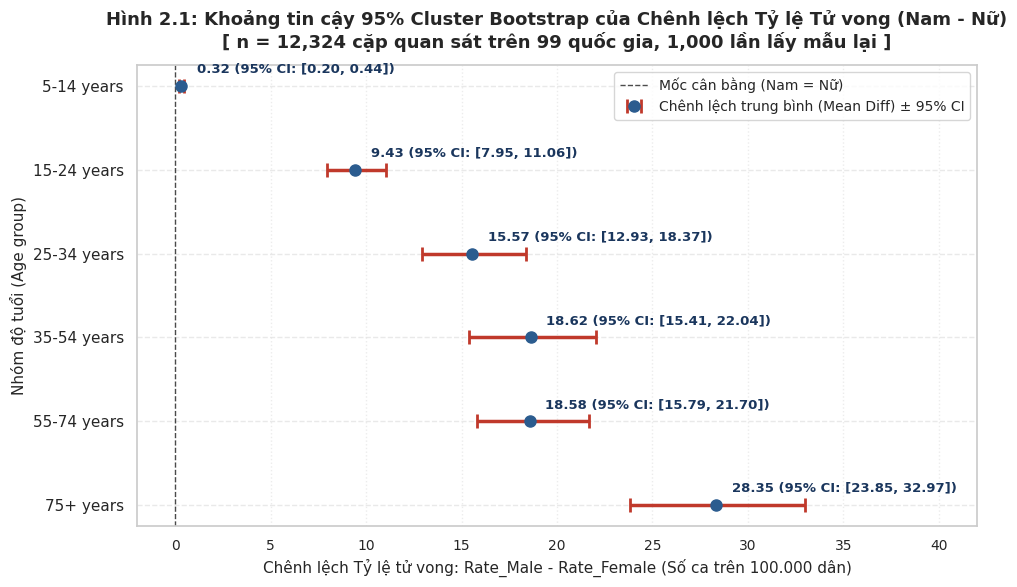

In [10]:
# 3. Biểu đồ 2.1: Forest Plot biểu diễn Chênh lệch trung bình Nam – Nữ kèm 95% Cluster Bootstrap CI
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(age_order))
means = q2_summary_df['Hiệu số trung bình (Mean Diff)'].values
ci_lows = q2_summary_df['95% CI Cận dưới'].values
ci_highs = q2_summary_df['95% CI Cận trên'].values
errors = [means - ci_lows, ci_highs - means]

# Vẽ thanh sai số (Error bars / Forest plot)
ax.errorbar(means, y_pos, xerr=errors, fmt='o', color='#2b5c8f', ecolor='#c0392b',
            elinewidth=2.5, capsize=5, capthick=2, markersize=8, label='Chênh lệch trung bình (Mean Diff) ± 95% CI')

# Đường mốc 0 (Zero line - Mốc không có sự chênh lệch giới)
ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7, label='Mốc cân bằng (Nam = Nữ)')

# Chú thích số liệu cụ thể bên cạnh mỗi điểm
for i, (m, low, high) in enumerate(zip(means, ci_lows, ci_highs)):
    ax.text(m + 0.8, i - 0.15, f"{m:.2f} (95% CI: [{low:.2f}, {high:.2f}])", fontsize=9.5, fontweight='bold', color='#1a365d')

ax.set_yticks(y_pos)
ax.set_yticklabels(age_order, fontsize=11)
ax.invert_yaxis()  # Để nhóm 5-14 ở trên cùng, 75+ ở dưới cùng
ax.set_title('Hình 2.1: Khoảng tin cậy 95% Cluster Bootstrap của Chênh lệch Tỷ lệ Tử vong (Nam - Nữ)\n' 
             f'[ n = {len(paired_q2):,} cặp quan sát trên 99 quốc gia, 1,000 lần lấy mẫu lại ]', fontsize=13, pad=12)
ax.set_xlabel('Chênh lệch Tỷ lệ tử vong: Rate_Male - Rate_Female (Số ca trên 100.000 dân)', fontsize=11)
ax.set_ylabel('Nhóm độ tuổi (Age group)', fontsize=11)
ax.set_xlim(-2, 42)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


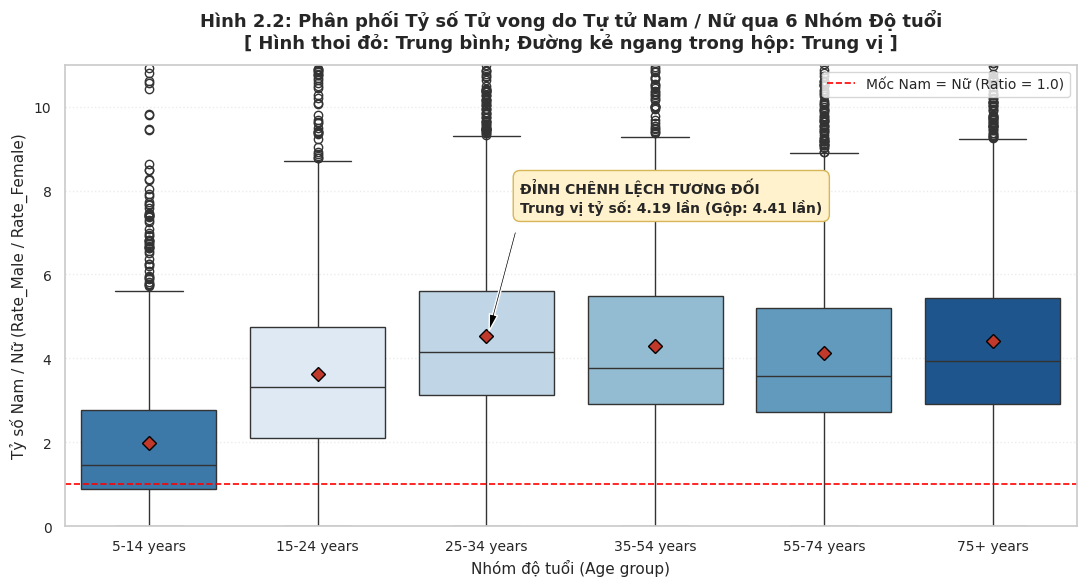

In [11]:
# 4. Biểu đồ 2.2: Phân phối Tỷ số Nam / Nữ (Sex Ratio) qua 6 nhóm tuổi (Boxplot + Strip plot)
# Lọc các tỷ số cực đoan > 15 để hiển thị trực quan rõ nét hình dạng phân phối
plot_ratio_df = valid_ratio[valid_ratio['rate_ratio'] <= 12].copy()

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=plot_ratio_df, x='age', y='rate_ratio', order=age_order,
    hue='age', palette='Blues', legend=False, showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': '#c0392b', 'markeredgecolor': 'black', 'markersize': 7},
    ax=ax
)

# Đường mốc tỷ số = 1 (Tỷ lệ Nam bằng Nữ)
ax.axhline(1, color='red', linestyle='--', linewidth=1.2, label='Mốc Nam = Nữ (Ratio = 1.0)')

# Ghi chú đỉnh chênh lệch ở nhóm 25-34 tuổi
med_25_34 = q2_summary_df.loc[q2_summary_df['Nhóm tuổi'] == '25-34 years', 'Trung vị Tỷ số (Median Ratio)'].values[0]
pool_25_34 = q2_summary_df.loc[q2_summary_df['Nhóm tuổi'] == '25-34 years', 'Tỷ số gộp (Pooled Ratio)'].values[0]
ax.annotate(
    f'ĐỈNH CHÊNH LỆCH TƯƠNG ĐỐI\nTrung vị tỷ số: {med_25_34:.2f} lần (Gộp: {pool_25_34:.2f} lần)',
    xy=(2, pool_25_34), xytext=(2.2, 7.5),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
    fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff2cc', edgecolor='#d6b656')
)

ax.set_title('Hình 2.2: Phân phối Tỷ số Tử vong do Tự tử Nam / Nữ qua 6 Nhóm Độ tuổi\n' 
             '[ Hình thoi đỏ: Trung bình; Đường kẻ ngang trong hộp: Trung vị ]', fontsize=13, pad=12)
ax.set_xlabel('Nhóm độ tuổi (Age group)', fontsize=11)
ax.set_ylabel('Tỷ số Nam / Nữ (Rate_Male / Rate_Female)', fontsize=11)
ax.set_ylim(0, 11)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q2)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng & 95% CI):
1. **Nam giới cao áp đảo nữ giới ở mọi lứa tuổi:**
   - Toàn bộ khoảng tin cậy 95% Cluster Bootstrap của mức chênh lệch trung bình $(\text{Rate}_{\text{Nam}} - \text{Rate}_{\text{Nữ}})$ ở cả 6 nhóm tuổi **đều hoàn toàn nằm trên mức 0** ($p < 0.001$). Điều này khẳng định hiện tượng nam giới có nguy cơ tử vong do tự tử cao hơn nữ giới là một quy luật có ý nghĩa thống kê phổ quát trên toàn cầu.
2. **Xu hướng chênh lệch tuyệt đối tăng dần theo tuổi:**
   - Nhóm trẻ em `5-14 years`: Mức chênh lệch rất nhỏ: **0.32 ca/100k** (95% CI: [0.20, 0.44]).
   - Nhóm thanh thiếu niên `15-24 years`: Chênh lệch tăng vọt lên **9.43 ca/100k** (95% CI: [7.95, 11.06]).
   - Nhóm trung niên `35-54 years`: Chênh lệch đạt **18.62 ca/100k** (95% CI: [15.41, 22.04]).
   - Nhóm người cao tuổi `75+ years`: **Chênh lệch tuyệt đối lớn nhất**, đạt tới **28.35 ca/100k** (95% CI: [23.85, 32.97]).

#### b) Phát hiện nghịch lý then chốt (Key Surprising Finding: Tuyệt đối vs Tương đối):
- **Người cao tuổi ($75+$) giữ kỷ lục về HIỆU SỐ TUYỆT ĐỐI:** Khoảng cách hiệu số giữa 2 giới đạt 28.35 ca/100k (tỷ lệ gộp nam lên tới 44.09 so với nữ 12.67 ca/100k).
- **Tuy nhiên, thanh niên trẻ ($25–34$ tuổi) lại giữ kỷ lục về TỶ SỐ TƯƠNG ĐỐI:** 
  - Tỷ số Nam/Nữ ở nhóm 25–34 tuổi đạt đỉnh cao nhất trong đời người: **Trung vị tỷ số là 4.19 lần** và **Tỷ số gộp toàn cầu lên tới 4.41 lần** (nam 21.83 so với nữ 4.95 ca/100k), cao hơn cả nhóm người già 75+ (tỷ số gộp 3.48 lần).
  - Đây là một phát hiện bất ngờ và có giá trị phản biện cao: *Nếu chỉ nhìn vào hiệu số tuyệt đối, người ta sẽ tưởng nhóm người già có chênh lệch giới nghiêm trọng nhất, nhưng khi nhìn vào tỷ số tương đối, nhóm nam thanh niên trẻ mới là đối tượng bị đe dọa bất cân xứng nặng nề nhất!* 

#### c) Cơ chế tâm lý - xã hội giải thích (Psychosocial Explanations):
- **Tại sao nam thanh niên 25–34 tuổi lại có tỷ số chênh lệch cao nhất?**
  - *Áp lực kinh tế - xã hội:* Độ tuổi 25–34 là giai đoạn nam giới bước vào thị trường lao động, chịu áp lực khủng khiếp về kỳ vọng xã hội ("trụ cột gia đình", thành bại sự nghiệp, áp lực tài chính).
  - *Rào cản tìm kiếm sự giúp đỡ (Help-seeking stigma):* Định kiến giới tính khiến nam thanh niên thường kìm nén căng thẳng tâm lý, ít chia sẻ hay tìm đến bác sĩ tâm thần so với nữ giới.
  - *Phương thức gây hại:* Nam giới thường lựa chọn các phương thức tự sát có tính bạo lực và gây tử vong tức thì cao hơn nữ giới (Lethality paradox).
- **Tại sao người già 75+ tuổi có tỷ lệ tuyệt đối cao nhất?**
  - Do sự kết hợp của bệnh tật thể chất mãn tính, suy giảm khả năng tự phục vụ, và cảm giác cô đơn / mất mát bạn đời ở giai đoạn cuối đời.

#### d) Khuyến nghị chính sách y tế công cộng (Actionable Recommendations):
- **Chiến dịch can thiệp mục tiêu (Targeted Interventions):** Các chiến dịch phòng chống tự tử không thể áp dụng chung chung một công thức. Ngành y tế cần thiết kế **2 chiến lược can thiệp riêng biệt**:
  1. *Đối với Nam thanh niên 25–34 tuổi:* Cần lồng ghép các đường dây nóng tư vấn tâm lý vào nơi làm việc, các nền tảng mạng xã hội và môi trường doanh nghiệp; phá bỏ định kiến kỳ thị việc nam giới tìm kiếm sự trợ giúp tâm lý.
  2. *Đối với Người cao tuổi (55+ và 75+):* Cần lồng ghép tầm soát trầm cảm vào các trạm y tế cơ sở và hệ thống chăm sóc sức khỏe người cao tuổi, tăng cường mạng lưới hỗ trợ cộng đồng chống cô đơn.

---
## CÂU HỎI NGHIÊN CỨU 3 (Q3 - NON-ML)
### Biến động GDP bình quân đầu người và Tỷ lệ tử vong do tự tử trong nội bộ quốc gia

**Câu hỏi:** Khi GDP bình quân đầu người biến động trong nội bộ từng quốc gia (sai phân bậc nhất theo năm lịch), tỷ lệ tử vong do tự tử thay đổi cùng chiều hay ngược chiều, và mối quan hệ này khác nhau ra sao giữa 3 nhóm thu nhập GDP?

- **Người phụ trách:** Đăng
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D2 (Reshaping & time):** Gộp dữ liệu về cấp độ `country-year`, ghép cặp chính xác theo năm lịch thực tế ($t-1 \to t$ và $t-2 \to t$) để tránh ghép nhầm qua các năm bị gián đoạn.
  - **D3 (Derived variables):** Xây dựng biến tốc độ tăng trưởng kinh tế $\%\Delta \text{GDP}_{i,t} = 100 \times (\frac{\text{GDP}_{i,t}}{\text{GDP}_{i,t-1}} - 1)$ và sai phân tỷ lệ tự tử $\Delta \text{Rate}_{i,t} = \text{Rate}_{i,t} - \text{Rate}_{i,t-1}$.
  - **D4 (Controlling for a confounder):** Áp dụng phương pháp **Sai phân bậc nhất (First-difference)** trong nội bộ từng quốc gia nhằm triệt tiêu hoàn toàn các biến gây nhiễu cố định theo thời gian (văn hóa, tôn giáo, địa lý, thể chế nền); đồng thời phân tầng theo **3 nhóm thu nhập (GDP bình quân)**.
  - **D6 (Robustness check):** Kiểm tra tính vững trên 3 kịch bản: mở rộng độ trễ 2 năm (`lag = 2`), loại bỏ các cú sốc kinh tế cực đoan ($|\%\Delta \text{GDP}| > 20\%$), và kiểm tra riêng trên nhóm các quốc gia thu nhập cao.
- **Tính cấp thiết & Đối tượng thụ hưởng (Rationale & Target Stakeholders):** Cung cấp bằng chứng kinh tế lượng – dịch tễ cho các nhà hoạch định chính sách an sinh xã hội, Bộ Tài chính và cơ quan y tế công cộng nhằm làm rõ mức độ nhạy cảm của sức khỏe tâm thần trước các biến động kinh tế vĩ mô ngắn hạn.
- **Hàm ý chính sách & Quyết định can thiệp (Policy Implications & Actionable Interventions):** Hỗ trợ cân nhắc giá trị thực tiễn của biến số tăng trưởng GDP như một chỉ báo cảnh báo sớm hằng năm, từ đó quyết định có nên neo ngân sách phòng chống tự tử theo chu kỳ suy thoái kinh tế hay duy trì đầu tư ổn định dài hạn theo từng phân khúc thu nhập quốc gia.

### 1. Tiền xử lý dữ liệu và Tạo biến sai phân theo năm lịch (Preprocessing for Q3)
Áp dụng các quy tắc chuẩn hóa từ giai đoạn EDA để đảm bảo tính đồng nhất của đơn vị quan sát `(country, year)`:
- Chuẩn hóa tên cột (`gdp_per_capita ($)`, `gdp_for_year ($)`), kiểm tra tính duy nhất của khóa `(country, year, age, sex)` và chỉ giữ các quốc gia–năm có đủ $6 \times 2 = 12$ phân nhóm tuổi–giới.
- Tổng hợp số ca và dân số về cấp `country-year` để tính tỷ lệ chuẩn theo trọng số dân số (từ 5 tuổi trở lên), phân chia 96 quốc gia thành 3 nhóm thu nhập (`Thấp`, `Trung bình`, `Cao`) dựa trên thứ hạng GDP trung vị từng nước.
- Ghép cặp chính xác theo năm lịch ($t-1$ và $t-2$) và báo cáo đầy đủ số dòng trước/sau qua hàm `check_row_count`.

In [12]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))
from src.economy_age import WHO, age_comparison, associations, changes, complete_years, country_years, period_cohort
from src.visualization import plot_age_shares, plot_crisis, plot_crude_asr, plot_gdp_changes, save_figure, set_academic_style

set_academic_style()
output = root / "data" / "processed"

# 1. Làm sạch, gộp cấp quốc gia–năm và tạo cặp sai phân theo năm lịch (t-1 và t-2)
full = complete_years(pd.read_csv(root / "data" / "raw" / "master.csv"))
panel = country_years(full)
one_year = changes(panel, 1)
two_year = changes(panel, 2)

[Nhãn hợp lệ, dân số dương và số ca không âm]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,820
  • Thay đổi      : +0 dòng (+0.00%)

[Đủ 6 nhóm tuổi × 2 giới tại mỗi quốc gia–năm]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)

[Gộp thành quốc gia–năm, cộng số ca và dân số]
  • Số dòng trước : 27,660
  • Số dòng sau   : 2,305
  • Thay đổi      : -25,355 dòng (-91.67%)

[GDP bình quân dương để tính phần trăm]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,305
  • Thay đổi      : +0 dòng (+0.00%)

[Có cùng nước ở đúng năm t−1]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,148
  • Thay đổi      : -157 dòng (-6.81%)

[Có cùng nước ở đúng năm t−2]
  • Số dòng trước : 2,305
  • Số dòng sau   : 2,028
  • Thay đổi      : -277 dòng (-12.02%)



### 2. Phân tích tương quan và Sai phân nội bộ (Analysis for Q3)
Áp dụng mô hình **Sai phân bậc nhất (First-difference)** trong nội bộ từng quốc gia:
$$\Delta \text{Rate}_{i,t} = \text{Rate}_{i,t} - \text{Rate}_{i,t-k}, \qquad \%\Delta \text{GDP}_{i,t} = 100 \times \left(\frac{\text{GDP}_{i,t}}{\text{GDP}_{i,t-k}} - 1\right)$$
Đo lường mối liên hệ bằng cả hệ số tương quan tuyến tính (**Pearson $r$**), tương quan hạng (**Spearman $\rho$**) và **hệ số dốc hồi quy** quy đổi theo mỗi $+10$ điểm phần trăm tăng trưởng GDP.

> **Lưu ý phương pháp luận:** Không dùng hàm `.shift(1)` theo vị trí dòng vì dữ liệu có những quốc gia bị đứt quãng năm báo cáo; ghép theo khóa `(country, year + lag)` đảm bảo sai phân luôn đúng khoảng cách năm lịch thực tế.

In [13]:
# 2. Tính bảng tương quan và độ nhạy (Robustness checks - D6) trên các phân nhóm
q3_stats = associations(one_year, two_year)
display(q3_stats.round(4))

,Số cặp,Số nước,Pearson r,Spearman ρ,Δ tỷ lệ / +10% GDP
Mẫu,,,,,
1 năm,2148,96,-0.0289,-0.0544,-0.0449
2 năm,2028,94,-0.0737,-0.0982,-0.0771
"1 năm, |ΔGDP| ≤ 20%",1828,96,-0.0129,-0.0156,-0.0292
"1 năm, GDP thấp",655,32,-0.0140,-0.0747,-0.0236
"1 năm, GDP trung bình",735,32,-0.0639,-0.0665,-0.1007
"1 năm, GDP cao",758,32,-0.0043,-0.0198,-0.0056


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q3)
Xây dựng 2 biểu đồ chuẩn học thuật: biểu đồ phân tán hồi quy phân tầng theo 3 nhóm GDP và biểu đồ chuỗi thời gian kép quanh cú sốc kinh tế 2008–2009.

-> Đã lưu biểu đồ: d:\Desktop\project KHDL\data\processed\tv2_q3_gdp.png


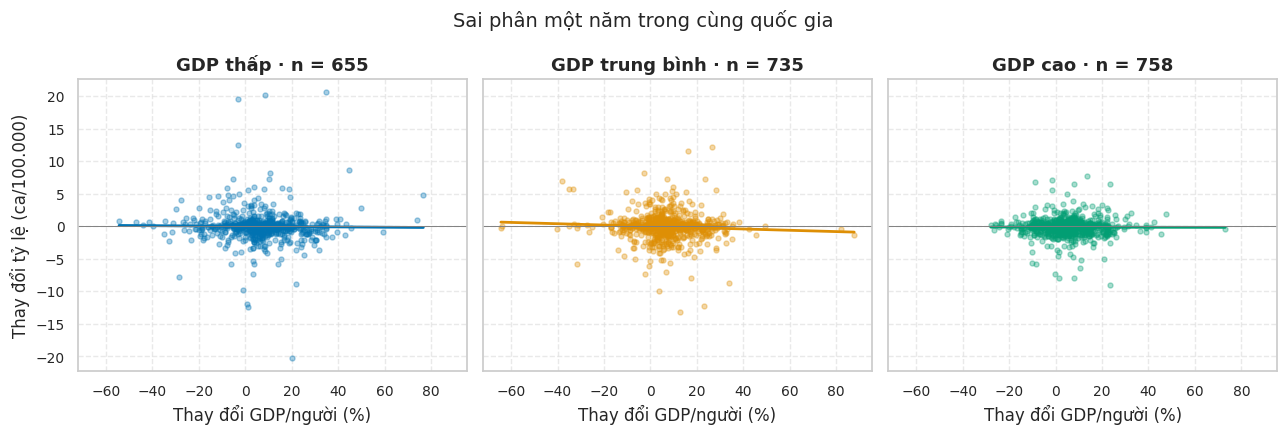

In [14]:
# 3. Biểu đồ 3.1: Phân tán và đường hồi quy %ΔGDP vs ΔRate phân tầng theo 3 nhóm thu nhập
fig = plot_gdp_changes(one_year)
save_figure(fig, output / "tv2_q3_gdp.png")
plt.show()

-> Đã lưu biểu đồ: d:\Desktop\project KHDL\data\processed\tv2_q3_crisis.png


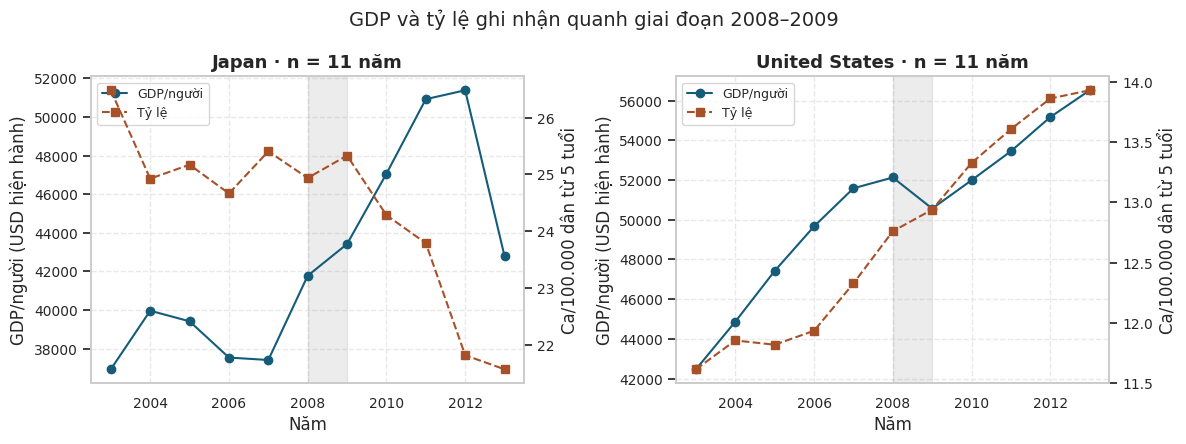

In [15]:
# 4. Biểu đồ 3.2: Diễn biến GDP/người và Tỷ lệ tự tử quanh khủng hoảng 2008–2009 (Nhật Bản & Mỹ)
fig = plot_crisis(panel)
save_figure(fig, output / "tv2_q3_crisis.png")
plt.show()

### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q3)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng cụ thể):
1. **Chiều hướng liên hệ nghịch chu kỳ rất yếu ở quy mô toàn mẫu:**
   - Trên **2,148 cặp năm liền kề của 96 quốc gia**, biến động GDP/người có tương quan âm rất nhẹ với biến động tỷ lệ tự tử: **Pearson $r = -0.0289$**, **Spearman $\rho = -0.0544$**.
   - Quy đổi theo độ dốc tuyến tính: khi tăng trưởng GDP/người cao hơn **+10 điểm phần trăm**, tỷ lệ tự tử trung bình chỉ giảm ước tính **$-0.0449$ ca/100,000 dân** (một biên độ thay đổi gần như không đáng kể về mặt lâm sàng so với mức nền ~12–14 ca/100k).
2. **Sự phân hóa rõ rệt giữa 3 nhóm thu nhập GDP (D4):**
   - **Nhóm GDP trung bình (735 cặp, 32 nước):** Thể hiện phản ứng nhạy nhất với biến động kinh tế ngắn hạn ($r = -0.0639$, $\rho = -0.0665$, hệ số dốc **$-0.1007$ ca/100k** cho mỗi +10% GDP).
   - **Nhóm GDP thấp (655 cặp, 32 nước):** Mối liên hệ rất yếu ($r = -0.0140$, $\rho = -0.0747$, hệ số dốc **$-0.0236$ ca/100k**).
   - **Nhóm GDP cao (758 cặp, 32 nước):** Gần như trơ với biến động GDP hằng năm ($r = -0.0043$, $\rho = -0.0198$, hệ số dốc chỉ **$-0.0056$ ca/100k**).

#### b) Giải thích cơ chế kinh tế - dịch tễ học:
- **Vì sao nhóm GDP cao ít dao động trước biến động GDP ngắn hạn?** Các quốc gia thu nhập cao (như Mỹ hay phần lớn Tây Âu) sở hữu mạng lưới an sinh xã hội, bảo hiểm thất nghiệp và hệ thống chăm sóc y tế tâm thần vững chắc giúp hấp thụ cú sốc thu nhập trong ngắn hạn; đồng thời, trường hợp Nhật Bản giai đoạn 2008–2009 cho thấy đường tỷ lệ tự tử chịu ảnh hưởng bởi xu hướng dài hạn và chính sách phòng chống quốc gia hơn là chỉ riêng biến động GDP danh nghĩa 1 năm.
- **Nhóm nước thu nhập trung bình** dễ bị tổn thương hơn khi gặp khủng hoảng hoặc chuyển đổi cơ cấu kinh tế do lưới an sinh chưa hoàn thiện bằng nhóm nước giàu.

#### c) Đánh giá tính vững của kết luận (Robustness Check - D6):
- **Mở rộng độ trễ 2 năm (`lag = 2`, 2,028 cặp trên 94 nước):** Mối tương quan âm tăng nhẹ lên **$r = -0.0737$**, **$\rho = -0.0982$** (hệ số dốc **$-0.0771$ ca/100k**), gợi ý tác động kinh tế có độ trễ tích lũy theo thời gian nhưng độ lớn vẫn nhỏ.
- **Loại bỏ cú sốc cực đoan ($|\%\Delta \text{GDP}| \le 20\%$, còn 1,828 cặp):** Tương quan giảm về gần 0 (**$r = -0.0129$**, **$\rho = -0.0156$**, độ dốc **$-0.0292$**), chứng tỏ phần lớn tín hiệu yếu ớt ban đầu chủ yếu đến từ một số ít năm khủng hoảng/lạm phát cực đoan chứ không phải quy luật phổ biến trong năm thường.

#### d) Hàm ý thực tiễn, Điểm bất ngờ và Giới hạn:
- **Điểm bất ngờ:** Trái với trực giác thông thường cho rằng suy thoái kinh tế luôn kéo tỷ lệ tự tử tăng vọt ngay lập tức trên diện rộng, biến động GDP danh nghĩa hằng năm thực chất **giải thích được rất ít biến thiên** tỷ lệ tự tử trong nội bộ từng quốc gia.
- **Hàm ý chính sách:** Cơ quan y tế không nên dùng tăng trưởng GDP hằng năm làm chỉ báo đơn lẻ để cắt giảm hay điều chỉnh ngân sách chăm sóc sức khỏe tâm thần; công tác dự phòng cần duy trì liên tục, đặc biệt ưu tiên củng cố lưới an sinh tại các nước thu nhập trung bình.
- **Giới hạn:** Biến `gdp_per_capita ($)` là GDP danh nghĩa tính bằng USD hiện hành, nên bị nhiễu bởi biến động tỷ giá hối đoái và lạm phát; ngoài ra, mô hình sai phân nội bộ không tách biệt được tác động của các yếu tố thay đổi đồng thời theo năm (thất nghiệp, chính sách y tế).

---
## CÂU HỎI NGHIÊN CỨU 4 (Q4 - NON-ML)
### Tác động của già hóa dân số: Tỷ lệ thô (Crude Rate) vs Tỷ lệ chuẩn hóa theo tuổi (Direct ASR)

**Câu hỏi:** Trong cùng tập hợp các quốc gia có dữ liệu đầy đủ ở cả hai giai đoạn 1995–2000 và 2010–2015, bao nhiêu phần biến động của tỷ lệ tử vong thô bị chi phối bởi sự dịch chuyển cơ cấu tuổi (già hóa dân số) so với mức giảm rủi ro thực chất theo Tỷ lệ chuẩn hóa trực tiếp theo tuổi (Direct ASR)?

- **Người phụ trách:** Đăng
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D2 (Reshaping & time):** Tổng hợp dữ liệu theo hai cửa sổ thời kỳ đối chứng dài 6 năm (**1995–2000** vs **2010–2015**) trên một tập thuần tập quốc gia cân bằng cố định đủ 12 năm.
  - **D3 (Derived variables):** Xây dựng **Tỷ lệ Chuẩn hóa Trực tiếp theo Độ tuổi (Direct Age-Standardized Rate - ASR)** theo bộ trọng số WHO 2000–2025 và thực hiện **Phân rã đối xứng Kitagawa** tách biệt thành phần *Cơ cấu tuổi* và *Tỷ lệ rủi ro theo tuổi*.
  - **D4 (Controlling for a confounder):** Khống chế triệt để biến gây nhiễu là **sự dịch chuyển cơ cấu dân số (già hóa dân số)** giữa hai giai đoạn lịch sử cách nhau 15 năm.
  - **D6 (Robustness check):** Đối chiếu kết quả chuẩn hóa theo **bộ trọng số WHO World Standard (2000–2025)** với **bộ trọng số thực nghiệm của chính tập mẫu (Empirical Sample Weights)**.
- **Tính cấp thiết & Đối tượng thụ hưởng (Rationale & Target Stakeholders):** Cung cấp công cụ hiệu chỉnh dịch tễ học chuẩn xác cho các nhà quản lý y tế công cộng, chuyên gia nhân khẩu học và Bộ Y tế các quốc gia đang đối mặt với tốc độ già hóa dân số nhanh.
- **Hàm ý chính sách & Quyết định can thiệp (Policy Implications & Actionable Interventions):** Ngăn ngừa sai lầm khi đánh giá hiệu quả chính sách y tế cộng đồng chỉ qua tỷ lệ thô: giúp phân biệt rạch ròi giữa việc *công tác phòng chống tự tử thất bại* với việc *tỷ lệ thô bị kéo lên do tỷ trọng người cao tuổi gia tăng*, qua đó điều chỉnh chính sách chăm sóc người cao tuổi kịp thời.

### 1. Tiền xử lý dữ liệu và Lọc thuần tập hai thời kỳ (Preprocessing for Q4)
Từ tập dữ liệu đầy đủ `full` (các quốc gia–năm có trọn vẹn 12 phân nhóm tuổi–giới), thực hiện các bước lọc cân bằng:
- Chọn 2 cửa sổ thời gian đối xứng gồm 6 năm lịch mỗi kỳ: **1995–2000** và **2010–2015**.
- Chỉ giữ lại các quốc gia xuất hiện đầy đủ cả **12/12 năm** ở hai cửa sổ để loại trừ sai lệch do thay đổi thành phần nước báo cáo (in số dòng trước/sau qua `check_row_count`).
- Chuẩn hóa bộ trọng số WHO 2000–2025 (tổng hợp về 6 nhóm tuổi từ 5 tuổi trở lên theo [bảng chuẩn NCI/SEER](https://seer.cancer.gov/stdpopulations/world.who.html)) và tính song song bộ trọng số thực nghiệm từ tổng dân số toàn mẫu.

In [16]:
# 1. Lọc tập thuần tập cân bằng 2 thời kỳ và đối chiếu 2 bộ trọng số chuẩn hóa (WHO vs Mẫu)
cohort = period_cohort(full)
empirical = full.groupby("age").population.sum()
weights = pd.DataFrame({"WHO": WHO / WHO.sum(), "Mẫu": empirical / empirical.sum()}).loc[WHO.index]
display(weights.round(4))

[Hai cửa sổ, mỗi cửa sổ 6 năm lịch]
  • Số dòng trước : 27,660
  • Số dòng sau   : 11,460
  • Thay đổi      : -16,200 dòng (-58.57%)

[Cùng quốc gia đủ cả 12 năm]
  • Số dòng trước : 11,460
  • Số dòng sau   : 7,056
  • Thay đổi      : -4,404 dòng (-38.43%)



,WHO,Mẫu
5-14 years,0.1896,0.1641
15-24 years,0.1831,0.1684
25-34 years,0.1704,0.1644
35-54 years,0.2758,0.2799
55-74 years,0.1474,0.1713
75+ years,0.0336,0.0518


### 2. Chuẩn hóa tuổi (Direct ASR) và Phân rã Kitagawa (Analysis for Q4)
Tính **Tỷ lệ chuẩn hóa trực tiếp theo độ tuổi (ASR)** cho từng quốc gia và cho toàn bộ mẫu gộp ở mỗi giai đoạn:
$$\text{ASR}_{p} = \sum_{a} \text{Rate}_{a,p} \times w_a$$
Đồng thời áp dụng **Phép phân rã đối xứng Kitagawa** cho biến thiên tỷ lệ thô $\Delta \text{Thô} = \text{Crude}_{2010\text{–}2015} - \text{Crude}_{1995\text{–}2000}$:
$$\Delta \text{Thô} = \underbrace{\sum_{a} (s_{a,1} - s_{a,0}) \frac{r_{a,1} + r_{a,0}}{2}}_{\text{Thành phần Cơ cấu tuổi}} + \underbrace{\sum_{a} (r_{a,1} - r_{a,0}) \frac{s_{a,1} + s_{a,0}}{2}}_{\text{Thành phần Tỷ lệ riêng theo tuổi}}$$
> **Lưu ý phương pháp luận:** Nếu thành phần *Cơ cấu tuổi* mang dấu dương (`+`) trong khi $\Delta \text{Thô}$ mang dấu âm (`-`), điều đó chứng tỏ quá trình già hóa dân số đang **kéo ngược chiều và che lấp bớt** thành quả giảm tỷ lệ tự tử thực chất ở từng nhóm tuổi.

In [17]:
# 2. Tính tỷ lệ thô, ASR (WHO & Mẫu) và phân rã biến thiên theo từng quốc gia & toàn mẫu
q4_rates, q4_delta, q4_shares = age_comparison(cohort, empirical)
pooled_rates, pooled_delta, pooled_shares = age_comparison(cohort, empirical, by_country=False)

display(pooled_rates.round(3), pooled_delta.round(3))
display(q4_delta.nlargest(15, "Δ dân số 55+ (điểm %)").round(3))

[Cộng số ca và dân số theo giai đoạn và nhóm tuổi]
  • Số dòng trước : 7,056
  • Số dòng sau   : 588
  • Thay đổi      : -6,468 dòng (-91.67%)

[Cộng số ca và dân số theo giai đoạn và nhóm tuổi]
  • Số dòng trước : 7,056
  • Số dòng sau   : 12
  • Thay đổi      : -7,044 dòng (-99.83%)



,WHO,Mẫu,Thô
period,,,
1995–2000,13.858,14.654,14.515
2010–2015,11.252,11.843,12.428


,Δ WHO,Δ Mẫu,Δ Thô,Cơ cấu tuổi,Tỷ lệ theo tuổi,Cơ cấu / Δ thô (%),Δ dân số 55+ (điểm %)
country,,,,,,,
Tất cả nước trong mẫu,-2.607,-2.81,-2.087,0.809,-2.896,-38.751,4.61


,Δ WHO,Δ Mẫu,Δ Thô,Cơ cấu tuổi,Tỷ lệ theo tuổi,Cơ cấu / Δ thô (%),Δ dân số 55+ (điểm %)
country,,,,,,,
Malta,1.554,1.563,1.887,0.203,1.684,10.754,10.279
Japan,-0.073,-0.623,-0.433,1.855,-2.288,-428.518,10.264
Singapore,-2.434,-2.985,-1.118,1.372,-2.489,-122.717,9.154
Republic of Korea,10.434,11.754,15.277,3.732,11.545,24.430,9.028
Finland,-8.687,-8.929,-9.319,0.105,-9.423,-1.122,8.353
Czech Republic,-2.099,-2.415,-1.325,1.373,-2.698,-103.646,7.620
Slovenia,-10.940,-11.322,-9.647,2.698,-12.345,-27.966,7.345
Mauritius,-5.079,-5.169,-5.160,0.086,-5.247,-1.675,7.134
Croatia,-5.922,-6.411,-4.726,2.517,-7.243,-53.249,6.922


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q4)
Xây dựng 2 biểu đồ chuyên sâu: Biểu đồ quả tạ (Dumbbell plot) đối chiếu biến động Tỷ lệ Thô vs Chuẩn WHO tại 15 nước già hóa nhanh nhất, và Biểu đồ cột chồng (Stacked bar chart) thể hiện sự dịch chuyển cơ cấu tuổi giữa hai thời kỳ.

-> Đã lưu biểu đồ: d:\Desktop\project KHDL\data\processed\tv2_q4_asr.png


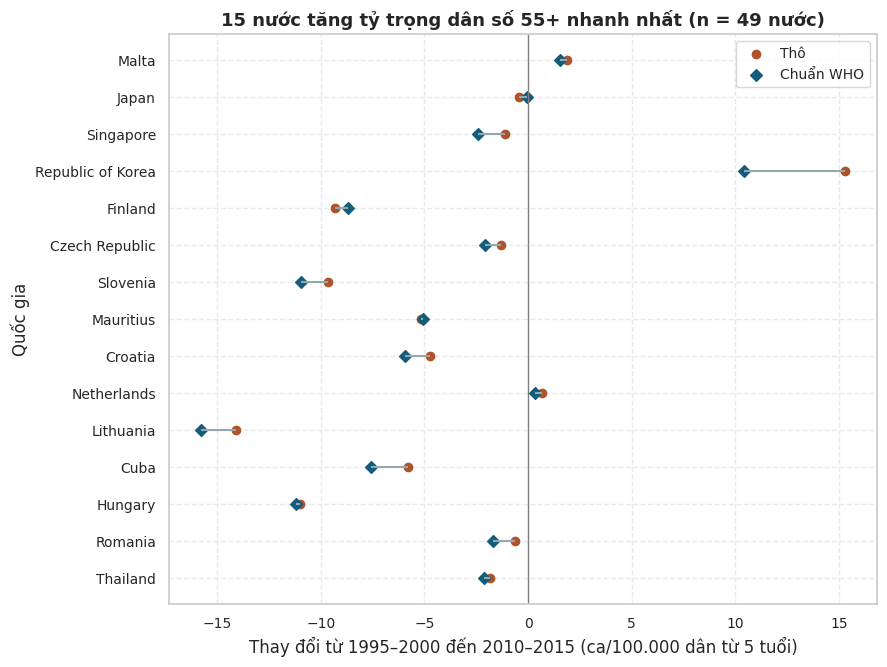

In [18]:
# 3. Biểu đồ 4.1: So sánh Δ Tỷ lệ Thô và Δ ASR chuẩn WHO tại top 15 quốc gia già hóa nhanh nhất
fig = plot_crude_asr(q4_delta)
save_figure(fig, output / "tv2_q4_asr.png")
plt.show()

-> Đã lưu biểu đồ: d:\Desktop\project KHDL\data\processed\tv2_q4_age.png


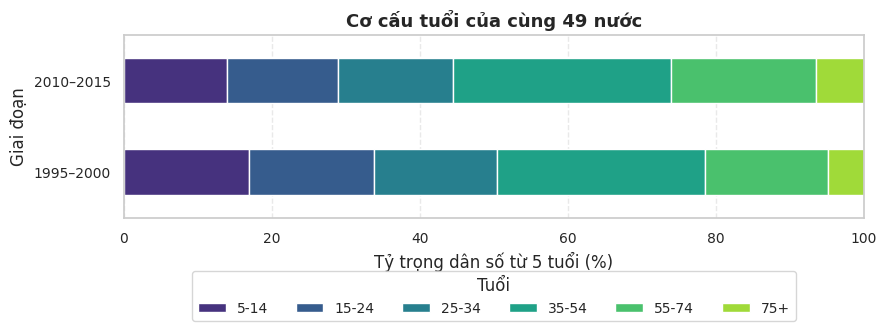

In [19]:
# 4. Biểu đồ 4.2: Dịch chuyển cơ cấu tỷ trọng 6 nhóm tuổi giữa giai đoạn 1995–2000 và 2010–2015
fig = plot_age_shares(pooled_shares, len(q4_delta))
save_figure(fig, output / "tv2_q4_age.png")
plt.show()

### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q4)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng cụ thể):
Trên tập thuần tập gồm **49 quốc gia** đủ dữ liệu cả 12 năm (`7,056` dòng quan sát):
1. **Tỷ lệ thô đánh giá thấp mức cải thiện thực chất:**
   - **Tỷ lệ Thô (Crude Rate)** giảm từ **14.515** (1995–2000) xuống **12.428** ca/100k (2010–2015), tức giảm **$-2.087$ ca/100k**.
   - Tuy nhiên, sau khi loại bỏ biến động cơ cấu tuổi bằng chuẩn **WHO ASR**, tỷ lệ chuẩn hóa giảm mạnh hơn từ **13.858** xuống **11.252** ca/100k, tức giảm tới **$-2.607$ ca/100k** (nhanh hơn khoảng 25% so với tỷ lệ thô).
2. **Phân rã định lượng tác động của già hóa dân số (Kitagawa Decomposition):**
   - Trong mức thay đổi thô **$-2.087$ ca/100k**, thành phần **rủi ro riêng theo từng độ tuổi** thực chất đã giảm rất sâu tới **$-2.896$ ca/100k**.
   - Nhưng sự **già hóa dân số (thay đổi cơ cấu tuổi)** đã đẩy tỷ lệ chung tăng ngược thêm **$+0.809$ ca/100k**, làm triệt tiêu tương đương **38.75%** nỗ lực giảm tỷ lệ thực chất! ($+0.809 - 2.896 = -2.087$).

#### b) Giải thích cơ chế nhân khẩu học:
- Giữa hai giai đoạn, tỷ trọng nhóm dân số lớn tuổi ($55+$) trong 49 quốc gia đã tăng thêm **+4.61 điểm phần trăm** (nhóm `55-74` tăng từ `16.70%` lên `19.62%`; nhóm `75+` tăng từ `4.79%` lên `6.48%`), trong khi nhóm trẻ em `5-14` thu hẹp từ `16.87%` xuống `13.91%`.
- Vì người cao tuổi có tỷ lệ tự tử nền cao hơn nhiều so với người trẻ, nên ngay cả khi từng nhóm tuổi đều giảm nguy cơ tự tử, việc "dân số già đi" vẫn tự động kéo tỷ lệ bình quân thô đi lên hoặc làm chậm đà giảm trên thống kê bề mặt.
- Ví dụ điển hình từ top 15 nước già hóa nhanh nhất: tại **Nhật Bản** (tỷ trọng 55+ tăng thêm **+10.264 điểm %**), tỷ lệ thô thậm chí bị kéo lệch đáng kể so với tốc độ thay đổi chuẩn WHO (`-0.073` ca/100k); hay **Singapore** (tỷ trọng 55+ tăng **+9.154 điểm %**) có ASR chuẩn WHO giảm `-2.434` ca/100k, sâu hơn mức giảm thô.

#### c) Đánh giá tính vững của kết luận (Robustness Check - D6):
- Khi thay đổi hệ quy chiếu từ **trọng số chuẩn WHO (`Δ WHO = -2.607`)** sang **trọng số thực nghiệm tính từ toàn bộ tập dữ liệu (`Δ Mẫu = -2.810`, giảm từ `14.654` xuống `11.843`)**, cả hai phương pháp chuẩn hóa đều cho kết quả nhất quán: **mức giảm chuẩn hóa theo tuổi luôn lớn hơn rõ rệt so với mức giảm của tỷ lệ thô (`-2.087`)**. Kết luận về hiệu ứng che khuất của già hóa dân số đạt tính vững cao.

#### d) Hàm ý thực tiễn, Điểm bất ngờ và Giới hạn:
- **Điểm bất ngờ:** Già hóa dân số là một "lực cản nhân khẩu học thầm lặng": ở quy mô 49 quốc gia, nó đóng góp mức tăng cơ học **$+0.809$ ca/100k**, che lấp hơn 1/3 thành quả giảm tỷ lệ tự tử theo từng độ tuổi (`-2.896` ca/100k).
- **Hàm ý chính sách:** Các báo cáo giám sát sức khỏe tâm thần quốc gia tại những nước có tốc độ già hóa nhanh (Nhật Bản, Hàn Quốc, châu Âu) **bắt buộc phải công bố song song Tỷ lệ chuẩn hóa theo tuổi (ASR)** bên cạnh tỷ lệ thô; đồng thời ưu tiên lồng ghép tầm soát trầm cảm vào hệ thống lão khoa.
- **Giới hạn:** Dữ liệu `master.csv` chỉ bắt đầu từ nhóm 5 tuổi trở lên nên trọng số WHO được chuẩn hóa lại trên dân số $5+$; phân tích cũng gộp hai giới tính trong từng nhóm tuổi và chỉ đại diện cho 49 quốc gia có dữ liệu đầy đủ 12 năm.

---
## CÂU HỎI NGHIÊN CỨU 5 (Q5 - NON-ML)
### Khảo sát cơ chế thiếu dữ liệu HDI và sai lệch ước lượng theo độ tuổi & khu vực địa lý

**Câu hỏi:** Chỉ số phát triển con người (`HDI for year`) bị thiếu như thế nào theo quốc gia, khu vực và thời gian? Nếu chỉ giữ các dòng có HDI (*complete-case analysis*) thì ước lượng tỷ lệ tự tử theo nhóm tuổi và khu vực bị lệch bao nhiêu?

- **Người phụ trách:** Kiên
- **Tiêu chí chiều sâu thỏa mãn:**
  - **D1 (Combining data):** Ghép bảng khu vực địa lý và nhóm thu nhập của World Bank (`data/raw/country_region.csv`) theo tên quốc gia; báo cáo số dòng trước/sau khi ghép, 11 tên nước không khớp và bảng ánh xạ.
  - **D2 (Reshaping & time):** Xây dựng ma trận trạng thái HDI theo quốc gia × năm giai đoạn 1985–2015; tách riêng nguồn *thiếu theo năm* và *thiếu theo quốc gia*.
  - **D3 (Derived variables):** Tạo cờ `is_missing_hdi`, biến phân loại nguồn thiếu `missing_type` và chỉ số sai lệch tương đối $\text{Bias}\%$.
  - **D4 (Controlling for a confounder):** Phân tầng $\text{Bias}\%$ theo 6 nhóm tuổi, giới tính, giai đoạn và khu vực địa lý.
  - **D5 (Quantifying uncertainty):** Kiểm định phi tham số hai mẫu (Mann-Whitney U, Kolmogorov-Smirnov) và khoảng tin cậy 95% cho $\text{Bias}\%$ bằng **cluster bootstrap theo quốc gia (1,000 lần lặp)**.
  - **D6 (Robustness check):** Tính lại $\text{Bias}\%$ khi bỏ Nga, bỏ 9 nước không bao giờ có HDI, chỉ giữ nước có độ phủ HDI $> 80\%$, và thay tỷ lệ gộp bằng trung vị.
- **Động cơ & Người dùng thụ hưởng (Target User):** Người phân tích dữ liệu y tế công cộng và các nhà dịch tễ học muốn đưa HDI vào mô hình (hồi quy, dự báo) trên bộ dữ liệu này. Cột HDI thiếu 69.94% (mục 3.2.4). Nhiều phân tích mặc định bỏ các dòng thiếu; nếu dữ liệu không thiếu hoàn toàn ngẫu nhiên (MCAR) thì cách đó làm sai lệch kết luận.
- **Quyết định hỗ trợ (Actionable Decision):** Có nên dùng HDI làm biến giải thích hay không; nếu dùng thì có được bỏ các dòng thiếu HDI không, hay phải phân tích riêng hoặc tìm nguồn HDI khác.

### 1. Tiền xử lý dữ liệu (Preprocessing for Q5)
- **Bước 1:** Đọc `master.csv`, đổi tên cột cho gọn, **loại năm 2016** (chỉ 16 nước và thiếu nhóm 5-14, xem mục 3.2.4).
- **Bước 2 (D1):** Ghép `data/raw/country_region.csv` để có khu vực và nhóm thu nhập của từng nước.
- **Bước 3 (D3):** Tạo cờ thiếu HDI và phân loại nguồn thiếu.
- **Bước 4:** Lọc riêng 10 năm có HDI để dùng cho các phân tích chỉ xét nguồn "thiếu theo quốc gia".
- Sau mỗi bước lọc hoặc ghép, số dòng trước/sau được in bằng hàm `check_row_count`.

> **Lưu ý phương pháp luận:** Tỷ lệ luôn tính theo công thức gộp $100{,}000 \times \sum \text{ca} / \sum \text{dân số}$, không lấy trung bình cột `suicides/100k pop`, vì các phân nhóm có quy mô dân số rất khác nhau.

In [20]:
%matplotlib inline
from IPython.display import display
from scipy import stats
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.visualization import save_figure

# Bước 1: đọc dữ liệu, đổi tên cột, loại năm 2016
q5_raw = pd.read_csv(os.path.join('..', 'data', 'raw', 'master.csv'))
q5 = q5_raw.rename(columns={
    'suicides/100k pop': 'rate',
    'HDI for year': 'hdi',
    ' gdp_for_year ($) ': 'gdp_for_year',
    'gdp_per_capita ($)': 'gdp_per_capita',
})
q5_before = q5
q5 = q5[q5['year'] != 2016].copy()
check_row_count(q5_before, q5, "Q5 - Loại năm 2016")
print("Nước chỉ có số liệu năm 2016 (bị loại theo):",
      sorted(set(q5_before['country']) - set(q5['country'])))

[Q5 - Loại năm 2016]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)

Nước chỉ có số liệu năm 2016 (bị loại theo): ['Mongolia']


**Bước 2 (D1): ghép khu vực và nhóm thu nhập.**

- **Nguồn:** World Bank, *Country and Lending Groups*, lấy qua API `https://api.worldbank.org/v2/country?format=json&per_page=400` ngày 23/11/2026, giấy phép CC BY 4.0. File `data/raw/country_region.csv` giữ 217 nền kinh tế (đã bỏ các dòng tổng hợp như "World", "High income") với 4 cột: `iso3`, `country_wb`, `region`, `income_group`.
- **Khóa ghép:** tên nước. Hai nguồn đặt tên khác nhau, nên nhóm ghép thử bằng tên gốc để liệt kê các tên không khớp, chuẩn hóa bằng một bảng ánh xạ tường minh, rồi mới ghép thật với `validate='many_to_one'` (mỗi nước chỉ có một dòng trong bảng vùng).
- **Lưu ý:** `income_group` là phân loại **hiện tại** của World Bank, không phải phân loại theo từng năm 1985–2015.
- **Kiểm tra số dòng:** đây là phép ghép trái nhiều–một, mỗi dòng chỉ được gắn thêm các cột của World Bank, nên số dòng phải giữ nguyên. Sau khi chuẩn hóa tên, không còn dòng nào thiếu khu vực.

In [21]:
q5_regions = pd.read_csv(os.path.join('..', 'data', 'raw', 'country_region.csv'))
assert q5_regions['country_wb'].is_unique
print(f"country_region.csv: {len(q5_regions)} nền kinh tế")

# Ghép thử bằng tên gốc để tìm khóa không khớp
q5_names = pd.Series(sorted(q5['country'].unique()))
q5_unmatched = q5_names[~q5_names.isin(q5_regions['country_wb'])]
print(f"Số nước trong dữ liệu: {len(q5_names)}, "
      f"không khớp tên: {len(q5_unmatched)}")

# Bảng ánh xạ tên của dữ liệu gốc -> tên của World Bank
Q5_NAME_MAP = {
    'Bahamas': 'Bahamas, The',
    'Czech Republic': 'Czechia',
    'Kyrgyzstan': 'Kyrgyz Republic',
    'Macau': 'Macao SAR, China',
    'Puerto Rico': 'Puerto Rico (US)',
    'Republic of Korea': 'Korea, Rep.',
    'Saint Kitts and Nevis': 'St. Kitts and Nevis',
    'Saint Lucia': 'St. Lucia',
    'Saint Vincent and Grenadines': 'St. Vincent and the Grenadines',
    'Slovakia': 'Slovak Republic',
    'Turkey': 'Turkiye',
}
assert set(Q5_NAME_MAP) == set(q5_unmatched)
assert set(Q5_NAME_MAP.values()) <= set(q5_regions['country_wb'])
display(pd.DataFrame({'Tên trong master.csv': list(Q5_NAME_MAP),
                      'Tên World Bank': list(Q5_NAME_MAP.values())}))

q5['country_wb'] = q5['country'].replace(Q5_NAME_MAP)
q5_before = q5
q5 = q5.merge(q5_regions, on='country_wb', how='left',
              validate='many_to_one')
check_row_count(q5_before, q5, "Q5 - Ghép khu vực World Bank (D1)")
print("Số dòng chưa có khu vực sau khi chuẩn hóa tên:",
      q5['region'].isna().sum())

# Tên khu vực tiếng Việt cho biểu đồ
Q5_REGION_VI = {
    'Europe & Central Asia': 'Châu Âu & Trung Á',
    'Latin America & Caribbean': 'Mỹ Latinh & Caribe',
    'East Asia & Pacific': 'Đông Á & Thái Bình Dương',
    'Middle East, North Africa, Afghanistan & Pakistan':
        'Trung Đông & Bắc Phi (gồm AF, PK)',
    'Sub-Saharan Africa': 'Châu Phi hạ Sahara',
    'North America': 'Bắc Mỹ',
    'South Asia': 'Nam Á',
}
q5['region_vi'] = q5['region'].map(Q5_REGION_VI)
q5_countries = q5.drop_duplicates('country')
display(q5_countries.groupby('region_vi').size()
        .sort_values(ascending=False).rename('Số quốc gia').to_frame())

country_region.csv: 217 nền kinh tế
Số nước trong dữ liệu: 100, không khớp tên: 11


,Tên trong master.csv,Tên World Bank
0,Bahamas,"Bahamas, The"
1,Czech Republic,Czechia
2,Kyrgyzstan,Kyrgyz Republic
3,Macau,"Macao SAR, China"
4,Puerto Rico,Puerto Rico (US)
5,Republic of Korea,"Korea, Rep."
6,Saint Kitts and Nevis,St. Kitts and Nevis
7,Saint Lucia,St. Lucia
8,Saint Vincent and Grenadines,St. Vincent and the Grenadines
9,Slovakia,Slovak Republic


[Q5 - Ghép khu vực World Bank (D1)]


  • Số dòng trước : 27,660
  • Số dòng sau   : 27,660
  • Thay đổi      : +0 dòng (+0.00%)

Số dòng chưa có khu vực sau khi chuẩn hóa tên: 0


,Số quốc gia
region_vi,
Châu Âu & Trung Á,46
Mỹ Latinh & Caribe,29
Đông Á & Thái Bình Dương,10
"Trung Đông & Bắc Phi (gồm AF, PK)",7
Châu Phi hạ Sahara,4
Bắc Mỹ,2
Nam Á,2


In [22]:
# Bước 3 (D3): cờ thiếu HDI và phân loại nguồn thiếu
q5_hdi_years = sorted(q5.loc[q5['hdi'].notna(), 'year'].unique())
q5['is_missing_hdi'] = q5['hdi'].isna()
q5['in_hdi_year'] = q5['year'].isin(q5_hdi_years)
q5['missing_type'] = np.select(
    [~q5['is_missing_hdi'], ~q5['in_hdi_year']],
    ['Có HDI', 'Thiếu theo năm'],
    default='Thiếu theo nước',
)
print("Các năm có HDI:", q5_hdi_years)

q5_cy = q5.drop_duplicates(['country', 'year'])
q5_type_table = pd.DataFrame({
    'Số dòng': q5['missing_type'].value_counts(),
    'Số cặp country-year': q5_cy['missing_type'].value_counts(),
})
q5_type_table['% số dòng'] = (100 * q5_type_table['Số dòng']
                              / len(q5)).round(2)
display(q5_type_table)

Các năm có HDI: [np.int64(1985), np.int64(1990), np.int64(1995), np.int64(2000), np.int64(2005), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]


,Số dòng,Số cặp country-year,% số dòng
missing_type,,,
Thiếu theo năm,18384,1532,66.46
Có HDI,8364,697,30.24
Thiếu theo nước,912,76,3.30


**Bước 4: lọc 10 năm có HDI.** HDI chỉ có ở các năm 1985, 1990, 1995, 2000, 2005 và 2010–2014; ở 21 năm còn lại mọi quốc gia đều thiếu HDI (*thiếu theo năm*). Các phân tích b)–e) ở mục 2 chỉ xét 10 năm này để tách riêng nguồn *thiếu theo quốc gia*. Số dòng giảm vì các dòng thuộc 21 năm không có HDI bị bỏ ra.

In [23]:
# Bước 4: chỉ giữ 10 năm có HDI
q5_h = q5[q5['in_hdi_year']]
check_row_count(q5, q5_h, "Q5 - Giữ 10 năm có HDI")
q5_hcy = q5_h.drop_duplicates(['country', 'year'])

[Q5 - Giữ 10 năm có HDI]
  • Số dòng trước : 27,660
  • Số dòng sau   : 9,276
  • Thay đổi      : -18,384 dòng (-66.46%)



### 2. Phân tích thống kê (Analysis for Q5)
Phần phân tích gồm 5 bước a)–e). Bảng số liệu của từng bước được in ngay bên dưới; biểu đồ tương ứng nằm ở mục 3.

**a) Thiếu theo thời gian và theo quốc gia (D2).** Dữ liệu được chuyển thành ma trận quốc gia × năm (*pivot*), mỗi ô mang một trong ba trạng thái: không có số liệu năm đó, có số liệu tự tử nhưng thiếu HDI, có HDI (Hình Q5.1). Bảng dưới đây cho tỷ lệ cặp country-year có HDI theo từng năm.

In [24]:
q5_status = (q5_cy.assign(code=np.where(q5_cy['is_missing_hdi'], 1, 2))
             .pivot(index='country', columns='year', values='code')
             .reindex(columns=range(1985, 2016))
             .fillna(0))
q5_order = q5_countries.sort_values(['region_vi', 'country'])
q5_status = q5_status.loc[q5_order['country']]

# Tỷ lệ country-year có HDI theo năm: các năm ngoài 10 năm có HDI đều là 0%
q5_by_year = q5_cy.groupby('year')['is_missing_hdi'].agg(['size', 'mean'])
q5_by_year['% có HDI'] = (100 * (1 - q5_by_year['mean'])).round(1)
assert (q5_by_year.drop(index=q5_hdi_years)['% có HDI'] == 0).all()
print("Tỷ lệ country-year có HDI trong 10 năm có HDI "
      "(21 năm còn lại đều 0%):")
display(q5_by_year.loc[q5_hdi_years]
        .rename(columns={'size': 'Số country-year'})
        [['Số country-year', '% có HDI']].T)

Tỷ lệ country-year có HDI trong 10 năm có HDI (21 năm còn lại đều 0%):


year,1985,1990,1995,2000,2005,2010,2011,2012,2013,2014
Số country-year,48.0,64.0,78.0,86.0,84.0,88.0,86.0,81.0,80.0,78.0
% có HDI,77.1,78.1,80.8,88.4,90.5,95.5,94.2,96.3,96.2,96.2


**b) Thiếu theo khu vực và nhóm thu nhập (D1, D4).** Để tách khỏi "thiếu theo năm" (năm đó cả thế giới không có HDI), phần này chỉ xét **10 năm có HDI** (bảng `q5_h` ở Bước 4). Đơn vị đếm là cặp country-year.

In [25]:
def q5_missing_by(col):
    # Tỷ lệ country-year thiếu HDI trong 10 năm có HDI
    t = q5_hcy.groupby(col).agg(
        so_quoc_gia=('country', 'nunique'),
        so_country_year=('country', 'size'),
        pct_thieu=('is_missing_hdi', 'mean'))
    t['pct_thieu'] = (100 * t['pct_thieu']).round(1)
    return t.sort_values('pct_thieu', ascending=False)


q5_miss_region = q5_missing_by('region_vi')
q5_miss_income = q5_missing_by('income_group')
display(q5_miss_region, q5_miss_income)

q5_never = q5_hcy.groupby('country')['is_missing_hdi'].all()
q5_never = q5_countries.set_index('country').loc[
    q5_never[q5_never].index, ['region_vi', 'income_group']]
q5_absent = sorted(set(q5['country']) - set(q5_h['country']))
print(f"Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: "
      f"{len(q5_never)}")
display(q5_never)
print("Nước không có dòng nào trong 10 năm có HDI:", q5_absent)

,so_quoc_gia,so_country_year,pct_thieu
region_vi,,,
Đông Á & Thái Bình Dương,9,66,21.2
Mỹ Latinh & Caribe,29,237,15.6
Châu Phi hạ Sahara,4,25,8.0
Châu Âu & Trung Á,46,372,6.2
Bắc Mỹ,2,19,0.0
Nam Á,2,6,0.0
"Trung Đông & Bắc Phi (gồm AF, PK)",7,48,0.0


,so_quoc_gia,so_country_year,pct_thieu
income_group,,,
Lower middle income,4,25,16.0
Upper middle income,36,253,9.9
High income,59,495,9.5


Nước có mặt trong 10 năm có HDI nhưng không bao giờ có HDI: 9


,region_vi,income_group
country,,
Aruba,Mỹ Latinh & Caribe,High income
Cabo Verde,Châu Phi hạ Sahara,Upper middle income
Dominica,Mỹ Latinh & Caribe,Upper middle income
Kiribati,Đông Á & Thái Bình Dương,Lower middle income
Puerto Rico,Mỹ Latinh & Caribe,High income
Republic of Korea,Đông Á & Thái Bình Dương,High income
Russian Federation,Châu Âu & Trung Á,High income
Saint Kitts and Nevis,Mỹ Latinh & Caribe,High income
San Marino,Châu Âu & Trung Á,High income


Nước không có dòng nào trong 10 năm có HDI: ['Macau']


**c) Độ lệch của complete-case (D3, D4).** Với mỗi phân nhóm, tỷ lệ gộp trên **mọi dòng** được so với tỷ lệ gộp trên **các dòng có HDI**:

$$\text{Bias}\% = \frac{\text{Rate}_{\text{Complete}} - \text{Rate}_{\text{All}}}{\text{Rate}_{\text{All}}} \times 100$$

Có hai phạm vi so sánh:

- **Toàn kỳ 1985–2015:** đúng với việc "xóa mọi dòng thiếu HDI". Độ lệch ở đây gộp cả hai nguồn thiếu, gồm cả tác động của việc chỉ còn 10 năm.
- **Trong 10 năm có HDI:** chỉ còn nguồn "thiếu theo nước". Đây là phạm vi chính để đánh giá thiên lệch chọn mẫu.

In [26]:
Q5_AGES = ['5-14 years', '15-24 years', '25-34 years', '35-54 years',
           '55-74 years', '75+ years']


def q5_bias_table(data, by):
    # Tỷ lệ gộp trên mọi dòng và trên các dòng có HDI, kèm Bias%
    cols = ['suicides_no', 'population']
    s_all = data.groupby(by)[cols].sum()
    s_cc = data[~data['is_missing_hdi']].groupby(by)[cols].sum()
    t = pd.DataFrame({
        'rate_all': 1e5 * s_all['suicides_no'] / s_all['population'],
        'rate_complete': 1e5 * s_cc['suicides_no'] / s_cc['population'],
    })
    t['bias_pct'] = 100 * (t['rate_complete'] - t['rate_all']) / t['rate_all']
    return t.round(2)


q5_overall = pd.DataFrame({
    'rate_all': [calculate_aggregated_rate(q5),
                 calculate_aggregated_rate(q5_h)],
    'rate_complete': [calculate_aggregated_rate(q5[~q5['is_missing_hdi']])] * 2,
}, index=['Toàn kỳ 1985–2015', 'Trong 10 năm có HDI'])
q5_overall['bias_pct'] = (100 * (q5_overall['rate_complete']
                                 - q5_overall['rate_all'])
                          / q5_overall['rate_all'])
print("Tổng thể:")
display(q5_overall.round(2))
print("Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI:",
      round(calculate_aggregated_rate(q5_h[q5_h['is_missing_hdi']]), 2))

q5_bias_age = pd.concat(
    {'Toàn kỳ': q5_bias_table(q5, 'age'),
     '10 năm có HDI': q5_bias_table(q5_h, 'age')}, axis=1).loc[Q5_AGES]
print("\nTheo nhóm tuổi:")
display(q5_bias_age)

q5_h = q5_h.assign(period=np.where(q5_h['year'] >= 2010,
                                   '2010–2014 (hằng năm)',
                                   '1985–2005 (5 năm/lần)'))
print("Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:")
display(q5_bias_table(q5_h, 'region_vi').sort_values('bias_pct'))
display(q5_bias_table(q5_h, 'sex'))
display(q5_bias_table(q5_h, 'period'))

Tổng thể:


,rate_all,rate_complete,bias_pct
Toàn kỳ 1985–2015,13.15,11.13,-15.39
Trong 10 năm có HDI,12.68,11.13,-12.24


Tỷ lệ gộp của riêng các dòng thiếu HDI trong 10 năm có HDI: 25.93

Theo nhóm tuổi:


Toàn kỳ                        10 năm có HDI                \
            rate_all rate_complete bias_pct      rate_all rate_complete   
age                                                                       
5-14 years      0.62          0.58    -6.93          0.64          0.58   
15-24 years     9.36          8.09   -13.64          9.18          8.09   
25-34 years    13.33         10.82   -18.83         12.82         10.82   
35-54 years    17.07         14.05   -17.72         16.14         14.05   
55-74 years    18.85         15.97   -15.28         17.69         15.97   
75+ years      24.54         20.97   -14.58         22.95         20.97   

                      
            bias_pct  
age                   
5-14 years     -9.21  
15-24 years   -11.87  
25-34 years   -15.58  
35-54 years   -12.93  
55-74 years    -9.70  
75+ years      -8.66

Trong 10 năm có HDI, theo khu vực, giới tính và giai đoạn:


,rate_all,rate_complete,bias_pct
region_vi,,,
Châu Âu & Trung Á,15.74,13.06,-17.02
Đông Á & Thái Bình Dương,16.33,14.97,-8.31
Châu Phi hạ Sahara,1.32,1.31,-0.99
Mỹ Latinh & Caribe,5.63,5.61,-0.42
Bắc Mỹ,13.15,13.15,0.00
Nam Á,33.92,33.92,0.00
"Trung Đông & Bắc Phi (gồm AF, PK)",3.97,3.97,0.00


,rate_all,rate_complete,bias_pct
sex,,,
female,5.75,5.20,-9.52
male,19.94,17.29,-13.29


,rate_all,rate_complete,bias_pct
period,,,
1985–2005 (5 năm/lần),13.72,11.86,-13.56
2010–2014 (hằng năm),11.86,10.57,-10.94


**d) Kiểm định và khoảng tin cậy (D5).**

- **So sánh phân phối:** trong 10 năm có HDI, tỷ lệ được gộp về cấp country-year, rồi nhóm thiếu HDI được so với nhóm có HDI bằng **Mann-Whitney U** (so vị trí, không giả định phân phối chuẩn) và **Kolmogorov-Smirnov** (so toàn bộ hình dạng phân phối). Hai kiểm định này coi các country-year là độc lập, trong khi các năm của cùng một nước thì tương quan với nhau, nên p-value chỉ mang tính tham khảo.
- **Khoảng tin cậy cho Bias%:** dùng `cluster_bootstrap_ci` trong `src/utils.py`, lấy mẫu lại **theo quốc gia** 1,000 lần. Cách này giữ nguyên sự phụ thuộc giữa các năm trong cùng một nước.

In [27]:
# Kiểm định trên tỷ lệ gộp cấp country-year
q5_cyr = (q5_h.groupby(['country', 'year'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cyr['rate'] = 1e5 * q5_cyr['suicides_no'] / q5_cyr['population']
q5_miss_r = q5_cyr.loc[q5_cyr['is_missing_hdi'], 'rate']
q5_have_r = q5_cyr.loc[~q5_cyr['is_missing_hdi'], 'rate']
q5_mwu = stats.mannwhitneyu(q5_miss_r, q5_have_r, alternative='two-sided')
q5_ks = stats.ks_2samp(q5_miss_r, q5_have_r)
print(f"Country-year thiếu HDI: n = {len(q5_miss_r)}, "
      f"trung vị = {q5_miss_r.median():.2f}/100k")
print(f"Country-year có HDI:   n = {len(q5_have_r)}, "
      f"trung vị = {q5_have_r.median():.2f}/100k")
print(f"Mann-Whitney U: U = {q5_mwu.statistic:,.1f}, "
      f"p = {q5_mwu.pvalue:.4f}")
print(f"Kolmogorov-Smirnov: D = {q5_ks.statistic:.4f}, "
      f"p = {q5_ks.pvalue:.4f}")

# Kiểm định theo từng nhóm tuổi (tỷ lệ gộp hai giới, cấp country-year-age)
q5_cya = (q5_h.groupby(['country', 'year', 'age'])
          .agg(suicides_no=('suicides_no', 'sum'),
               population=('population', 'sum'),
               is_missing_hdi=('is_missing_hdi', 'first'))
          .reset_index())
q5_cya['rate'] = 1e5 * q5_cya['suicides_no'] / q5_cya['population']
q5_age_tests = []
for age in Q5_AGES:
    g = q5_cya[q5_cya['age'] == age]
    a = g.loc[g['is_missing_hdi'], 'rate']
    b = g.loc[~g['is_missing_hdi'], 'rate']
    q5_age_tests.append({
        'age': age, 'n_thieu': len(a), 'n_co': len(b),
        'trung_vi_thieu': round(a.median(), 2),
        'trung_vi_co': round(b.median(), 2),
        'p_mann_whitney': stats.mannwhitneyu(
            a, b, alternative='two-sided').pvalue,
    })
q5_age_tests = pd.DataFrame(q5_age_tests).set_index('age')
display(q5_age_tests.round(4))


def q5_bias_pct(data):
    # Bias% tổng thể của một tập dữ liệu (dùng cho bootstrap)
    r_all = calculate_aggregated_rate(data)
    r_cc = calculate_aggregated_rate(data[~data['is_missing_hdi']])
    return 100 * (r_cc - r_all) / r_all


q5_ci = cluster_bootstrap_ci(
    q5_h[['country', 'suicides_no', 'population', 'is_missing_hdi']],
    cluster_col='country', calc_func=q5_bias_pct,
    n_bootstraps=1000, random_state=42)
print(f"Bias% trong 10 năm có HDI: {q5_bias_pct(q5_h):.2f}% "
      f"(KTC 95% cluster bootstrap: {q5_ci[0]:.2f}% đến {q5_ci[1]:.2f}%)")

Country-year thiếu HDI: n = 76, trung vị = 8.53/100k


Country-year có HDI:   n = 697, trung vị = 10.35/100k
Mann-Whitney U: U = 25,028.5, p = 0.4306
Kolmogorov-Smirnov: D = 0.1189, p = 0.2639


,n_thieu,n_co,trung_vi_thieu,trung_vi_co,p_mann_whitney
age,,,,,
5-14 years,76,697,0.40,0.40,0.1240
15-24 years,76,697,7.01,7.33,0.1688
25-34 years,76,697,10.47,9.40,0.5716
35-54 years,76,697,12.65,12.52,0.9646
55-74 years,76,697,11.85,12.60,0.9890
75+ years,76,697,11.40,13.65,0.4833


Bias% trong 10 năm có HDI: -12.24% (KTC 95% cluster bootstrap: -29.07% đến 0.18%)


**e) Kiểm tra độ vững (D6).** Tỷ lệ gộp bị chi phối bởi các nước đông dân, nên Bias% (trong 10 năm có HDI) được tính lại khi thay đổi cách tính:

1. **Bỏ Nga:** Nga đông dân, tỷ lệ cao và không bao giờ có HDI.
2. **Bỏ 9 nước không bao giờ có HDI:** chỉ còn các nước thiếu HDI ở một vài năm.
3. **Chỉ nước có độ phủ HDI > 80%** (độ phủ = tỷ lệ country-year có HDI trong 10 năm có HDI), và so với nhóm nước có độ phủ < 30%.
4. **Dùng trung vị** tỷ lệ cấp country-year thay cho tỷ lệ gộp.

In [28]:
q5_cov = 1 - q5_hcy.groupby('country')['is_missing_hdi'].mean()
q5_high = q5_cov[q5_cov > 0.8].index
q5_low = q5_cov[q5_cov < 0.3].index
print(f"Độ phủ HDI > 80%: {len(q5_high)} nước; < 30%: {len(q5_low)} nước; "
      f"30–80%: {len(q5_cov) - len(q5_high) - len(q5_low)} nước")
print(f"Tỷ lệ gộp nhóm độ phủ cao: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_high)]):.2f}"
      f"; nhóm độ phủ thấp: "
      f"{calculate_aggregated_rate(q5_h[q5_h['country'].isin(q5_low)]):.2f}"
      " (ca/100k)")

q5_variants = {
    'Chính: mọi nước, tỷ lệ gộp': q5_h,
    'Bỏ Nga': q5_h[q5_h['country'] != 'Russian Federation'],
    'Bỏ 9 nước không bao giờ có HDI':
        q5_h[~q5_h['country'].isin(q5_never.index)],
    'Chỉ nước có độ phủ HDI > 80%': q5_h[q5_h['country'].isin(q5_high)],
}
q5_robust = pd.DataFrame({
    name: {'so_nuoc': d['country'].nunique(),
           'rate_all': calculate_aggregated_rate(d),
           'rate_complete': calculate_aggregated_rate(
               d[~d['is_missing_hdi']]),
           'bias_pct': q5_bias_pct(d)}
    for name, d in q5_variants.items()}).T
q5_med_all = q5_cyr['rate'].median()
q5_med_cc = q5_have_r.median()
q5_robust.loc['Trung vị country-year thay cho tỷ lệ gộp'] = [
    q5_h['country'].nunique(), q5_med_all, q5_med_cc,
    100 * (q5_med_cc - q5_med_all) / q5_med_all]
q5_robust['so_nuoc'] = q5_robust['so_nuoc'].astype(int)
display(q5_robust.round(2))

Độ phủ HDI > 80%: 78 nước; < 30%: 9 nước; 30–80%: 12 nước
Tỷ lệ gộp nhóm độ phủ cao: 11.17; nhóm độ phủ thấp: 26.83 (ca/100k)


,so_nuoc,rate_all,rate_complete,bias_pct
"Chính: mọi nước, tỷ lệ gộp",99,12.68,11.13,-12.24
Bỏ Nga,98,11.46,11.13,-2.91
Bỏ 9 nước không bao giờ có HDI,90,11.13,11.13,-0.03
Chỉ nước có độ phủ HDI > 80%,78,11.17,11.17,-0.02
Trung vị country-year thay cho tỷ lệ gộp,99,10.06,10.35,2.88


### 3. Trực quan hóa và Kết quả (Results & Visualizations for Q5)
Bốn biểu đồ dưới đây trình bày kết quả của mục 2:
- **Hình Q5.1 (D2):** ma trận trạng thái HDI theo quốc gia × năm. Ô xám là năm nước đó không có trong dữ liệu, ô cam là có số liệu tự tử nhưng thiếu HDI, ô xanh là có HDI.
- **Hình Q5.2 (D1, D4):** tỷ lệ thiếu HDI theo khu vực và nhóm thu nhập trong 10 năm có HDI.
- **Hình Q5.3 (D3, D4, D5):** tỷ lệ tự tử theo nhóm tuổi trên mọi dòng so với complete-case, kèm Bias% và p-value Mann-Whitney U.
- **Hình Q5.4 (D6):** Bias% dưới các cách tính khác nhau.

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig1_hdi_matrix.png


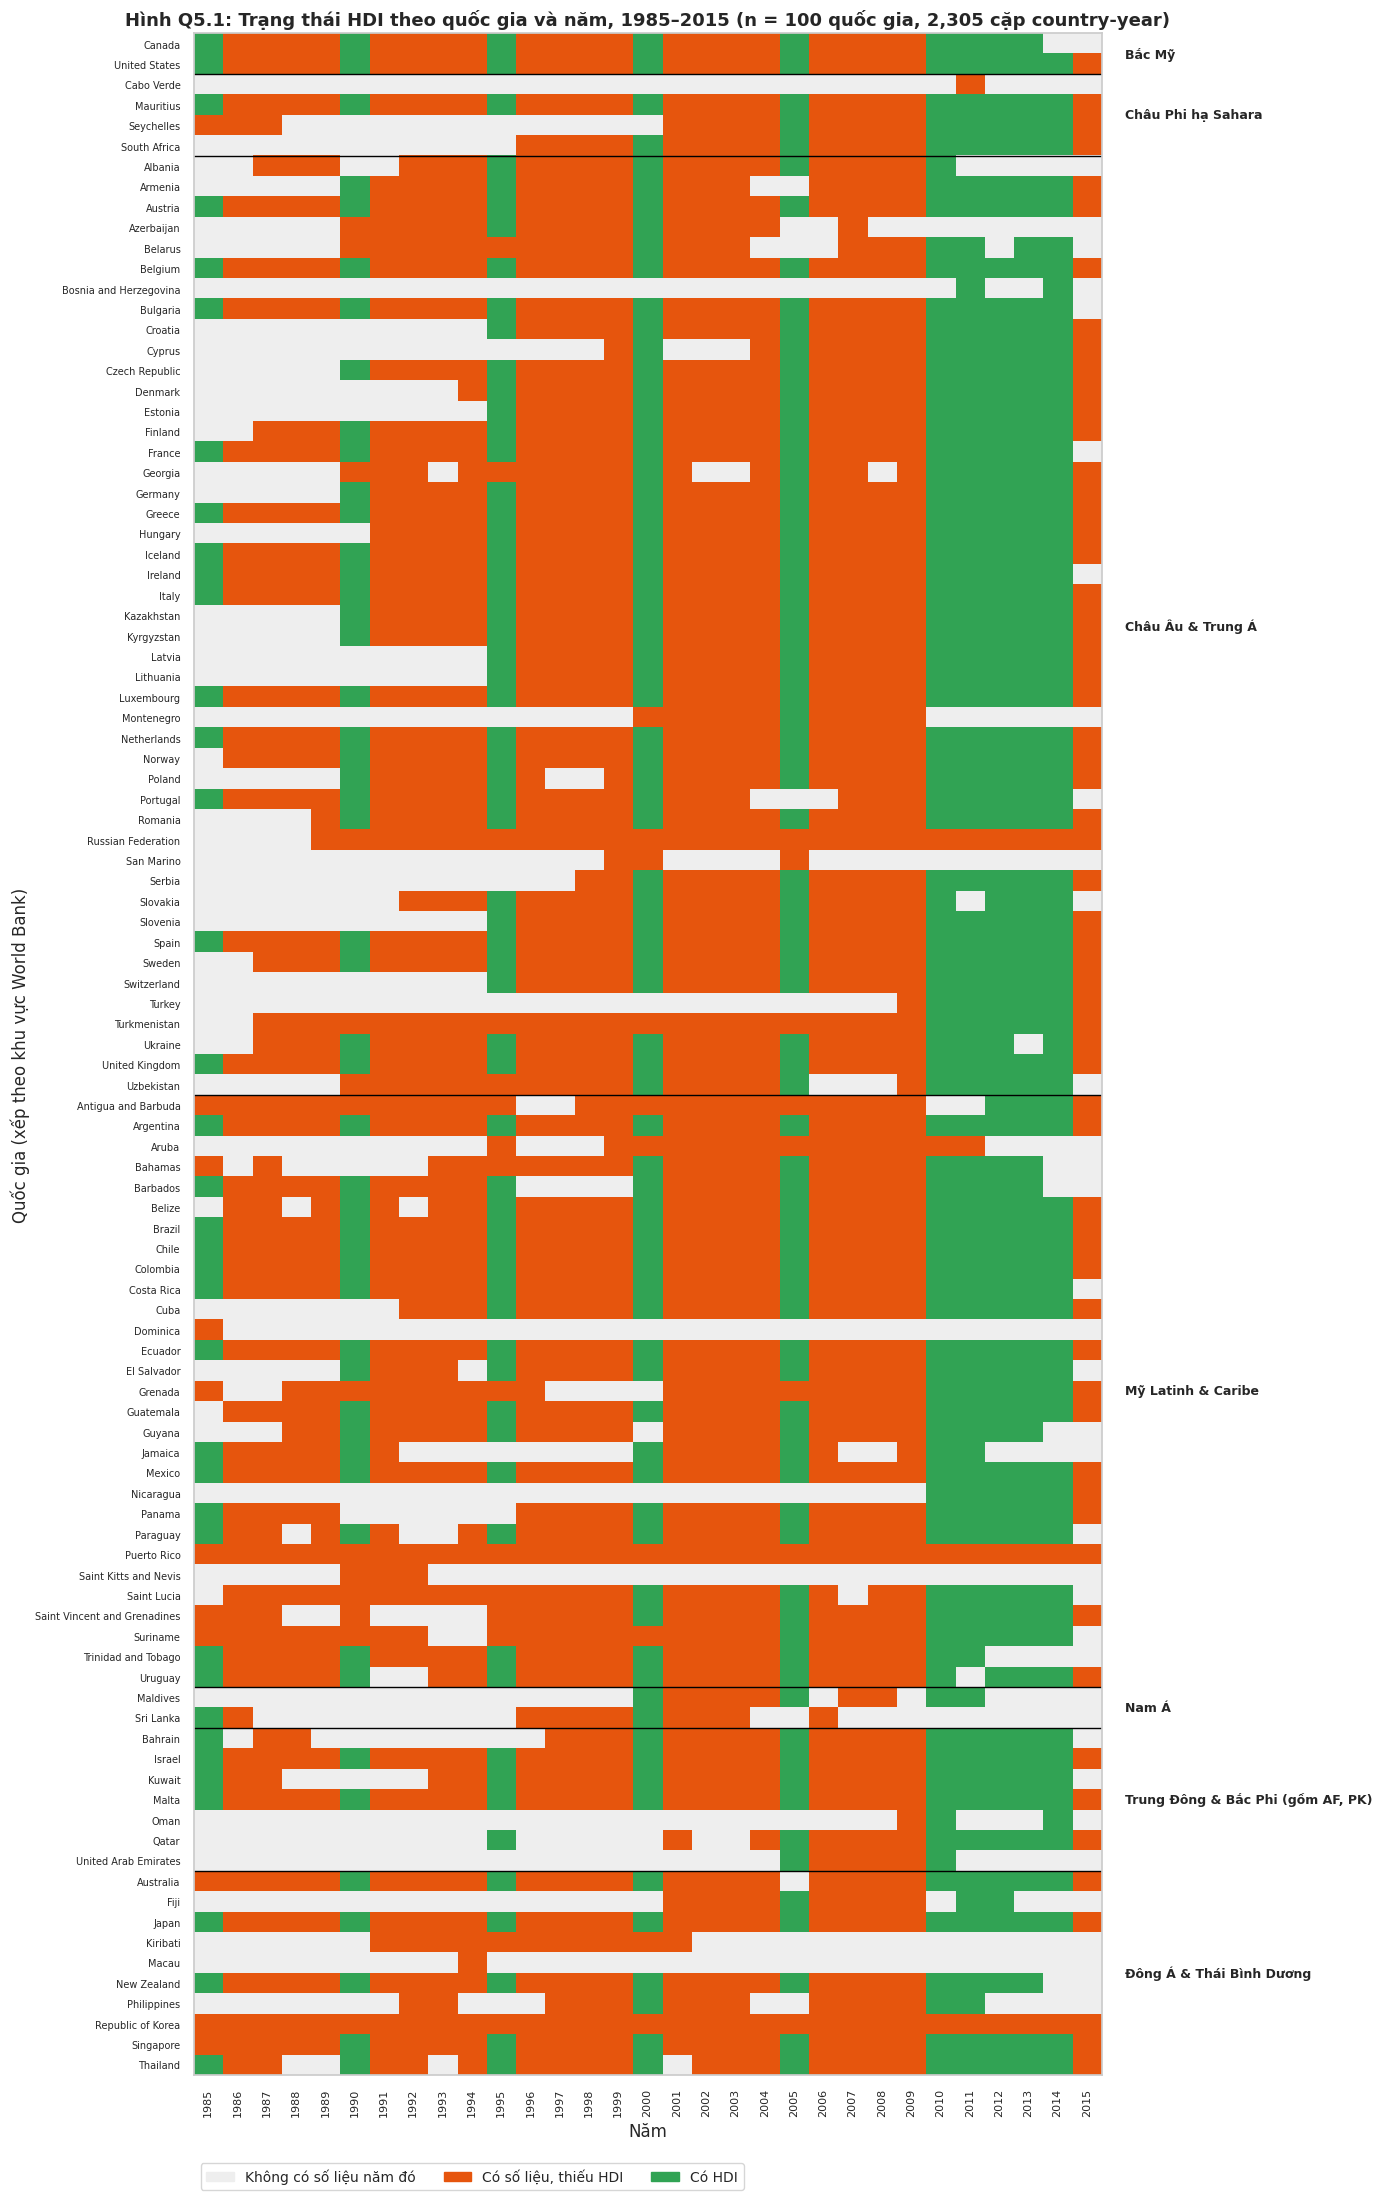

In [29]:
fig, ax = plt.subplots(figsize=(14, 22))
cmap = ListedColormap(['#eeeeee', '#e6550d', '#31a354'])
ax.imshow(q5_status.to_numpy(), aspect='auto', cmap=cmap,
          vmin=0, vmax=2, interpolation='none')
ax.set_xticks(range(q5_status.shape[1]))
ax.set_xticklabels(q5_status.columns, rotation=90, fontsize=8)
ax.set_yticks(range(q5_status.shape[0]))
ax.set_yticklabels(q5_status.index, fontsize=7)
ax.grid(False)

# Đường phân cách và nhãn khu vực
q5_bounds = q5_order['region_vi'].to_numpy()
for i in range(1, len(q5_bounds)):
    if q5_bounds[i] != q5_bounds[i - 1]:
        ax.axhline(i - 0.5, color='black', linewidth=1)
for reg_name, pos in (q5_order.reset_index(drop=True)
                      .groupby('region_vi').groups.items()):
    ax.text(q5_status.shape[1] + 0.3, np.mean(pos), reg_name,
            va='center', fontsize=9, fontweight='bold')

ax.legend(handles=[Patch(color='#eeeeee', label='Không có số liệu năm đó'),
                   Patch(color='#e6550d', label='Có số liệu, thiếu HDI'),
                   Patch(color='#31a354', label='Có HDI')],
          loc='upper left', bbox_to_anchor=(0, -0.04), ncol=3)
ax.set_xlabel('Năm')
ax.set_ylabel('Quốc gia (xếp theo khu vực World Bank)')
ax.set_title('Hình Q5.1: Trạng thái HDI theo quốc gia và năm, 1985–2015 '
             f'(n = {q5_status.shape[0]} quốc gia, '
             f'{len(q5_cy):,} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig1_hdi_matrix.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig2_missing_by_region.png


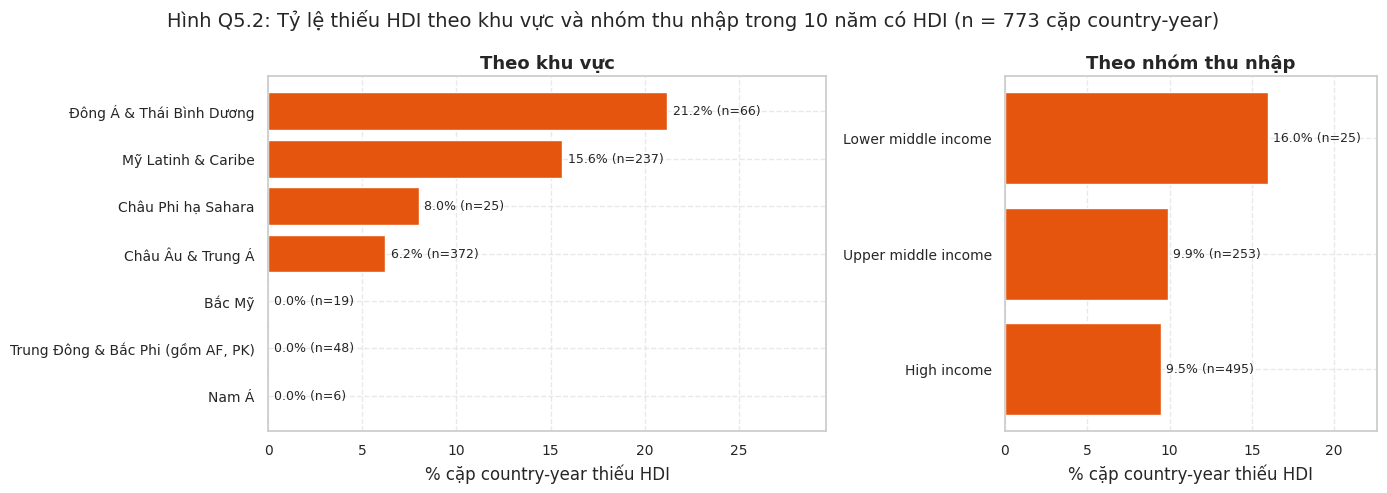

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         gridspec_kw={'width_ratios': [3, 2]})
for ax, t, title in [(axes[0], q5_miss_region, 'Theo khu vực'),
                     (axes[1], q5_miss_income, 'Theo nhóm thu nhập')]:
    t = t.sort_values('pct_thieu')
    ax.barh(t.index, t['pct_thieu'], color='#e6550d')
    for i, (p, n) in enumerate(zip(t['pct_thieu'], t['so_country_year'])):
        ax.text(p + 0.3, i, f"{p:.1f}% (n={n})", va='center', fontsize=9)
    ax.set_xlabel('% cặp country-year thiếu HDI')
    ax.set_title(title)
    ax.set_xlim(0, t['pct_thieu'].max() * 1.35 + 1)
fig.suptitle('Hình Q5.2: Tỷ lệ thiếu HDI theo khu vực và nhóm thu nhập '
             f'trong 10 năm có HDI (n = {len(q5_hcy)} cặp country-year)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig2_missing_by_region.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig3_bias_by_age.png


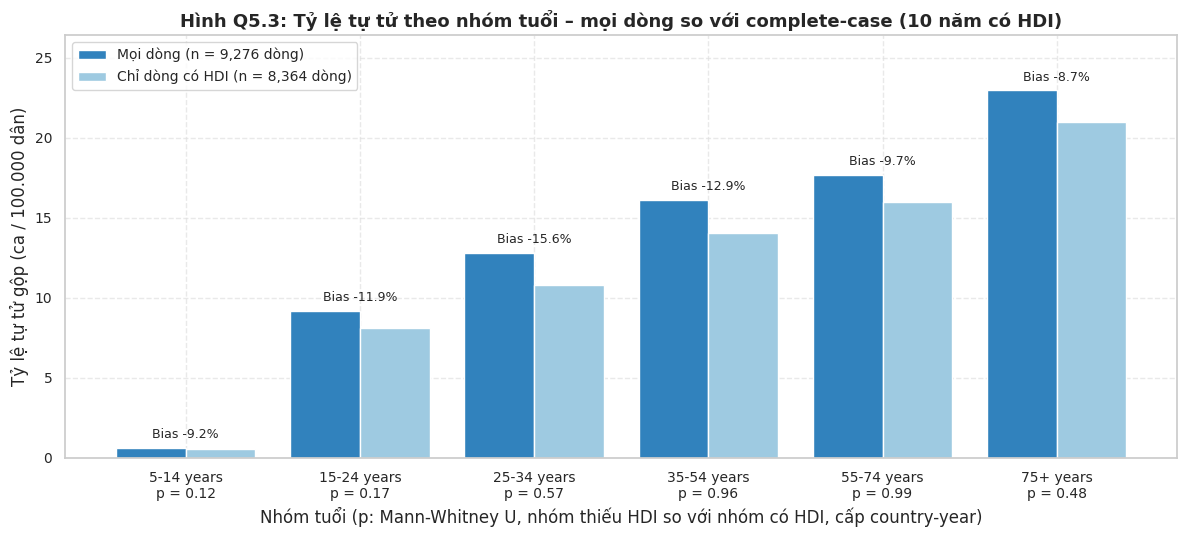

In [31]:
q5_plot = q5_bias_age['10 năm có HDI']
x = np.arange(len(Q5_AGES))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(x - 0.2, q5_plot['rate_all'], width=0.4, color='#3182bd',
       label=f'Mọi dòng (n = {len(q5_h):,} dòng)')
ax.bar(x + 0.2, q5_plot['rate_complete'], width=0.4, color='#9ecae1',
       label=f'Chỉ dòng có HDI (n = {(~q5_h["is_missing_hdi"]).sum():,} dòng)')
for i, (top, b) in enumerate(zip(q5_plot[['rate_all', 'rate_complete']]
                                 .max(axis=1), q5_plot['bias_pct'])):
    ax.text(i, top + 0.6, f"Bias {b:+.1f}%", ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\np = {p:.2f}" for a, p in
                    zip(Q5_AGES, q5_age_tests['p_mann_whitney'])])
ax.set_xlabel('Nhóm tuổi (p: Mann-Whitney U, nhóm thiếu HDI so với nhóm '
              'có HDI, cấp country-year)')
ax.set_ylabel('Tỷ lệ tự tử gộp (ca / 100.000 dân)')
ax.set_ylim(0, q5_plot['rate_all'].max() * 1.15)
ax.set_title('Hình Q5.3: Tỷ lệ tự tử theo nhóm tuổi – mọi dòng so với '
             'complete-case (10 năm có HDI)')
ax.legend(loc='upper left')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig3_bias_by_age.png')
plt.show()

-> Đã lưu biểu đồ: ../data/processed/tv3_q5_fig4_robustness.png


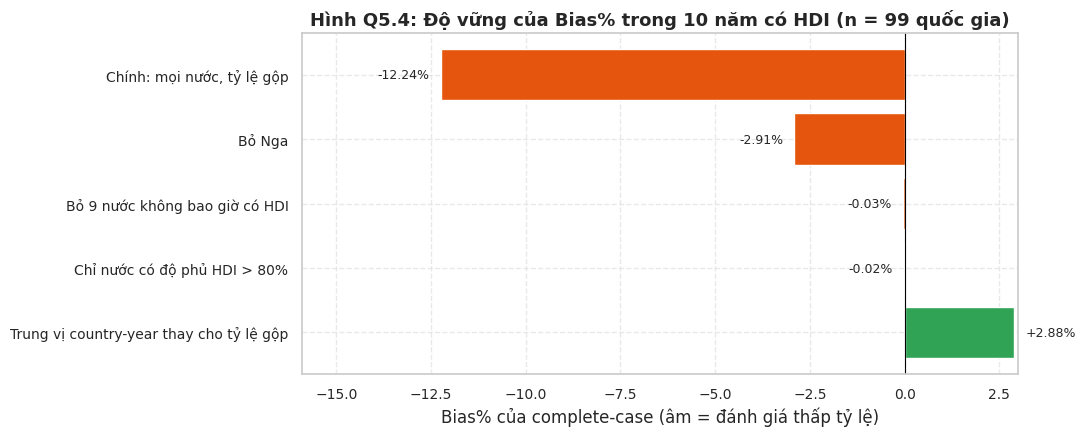

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.5))
q5_rb = q5_robust['bias_pct'][::-1]
ax.barh(q5_rb.index, q5_rb, color=np.where(q5_rb < 0, '#e6550d', '#31a354'))
for i, v in enumerate(q5_rb):
    ax.text(v - 0.3 if v < 0 else v + 0.3, i, f"{v:+.2f}%", va='center',
            ha='right' if v < 0 else 'left', fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(q5_rb.min() * 1.3, 3)
ax.set_xlabel('Bias% của complete-case (âm = đánh giá thấp tỷ lệ)')
ax.set_title('Hình Q5.4: Độ vững của Bias% trong 10 năm có HDI '
             f'(n = {q5_h["country"].nunique()} quốc gia)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q5_fig4_robustness.png')
plt.show()

### 4. Thảo luận và Đóng gói kết quả (Discussion & Insights for Q5)

#### a) Trả lời trực tiếp câu hỏi nghiên cứu (Bằng số liệu định lượng cụ thể):
1. **Cơ chế thiếu dữ liệu HDI không hoàn toàn ngẫu nhiên (Not MCAR):**
   - Trong tổng số 27,820 dòng gốc, `HDI for year` bị thiếu **69.94%** (19,456 dòng). Sau khi loại năm 2016 còn 27,660 dòng (100 quốc gia), dữ liệu thiếu tách thành 2 nguồn rõ rệt và **không phân bố ngẫu nhiên**: nhóm dòng thiếu HDI trong 10 năm công bố có tỷ lệ tự tử gộp lên tới **25.93 ca/100,000 dân**, cao hơn gấp đôi so với nhóm có HDI (**11.13 ca/100,000 dân**).
2. **Mức độ sai lệch của phân tích Complete-case (`Bias%`):**
   - **Tổng thể:** Trên toàn kỳ 1985–2015, việc loại bỏ toàn bộ dòng thiếu HDI làm tỷ lệ tự tử gộp giảm từ **13.15** xuống **11.13 ca/100k** (**Bias% = -15.39%**). Trong phạm vi chính **10 năm có HDI** (`9,276` dòng, `773` cặp `country-year`), tỷ lệ gộp giảm từ **12.68** xuống **11.13 ca/100k**, tương ứng **Bias% = -12.24%** (Khoảng tin cậy 95% *cluster bootstrap* theo quốc gia: **[-29.07%, +0.18%]**).
   - **Theo nhóm tuổi (trong 10 năm có HDI – Hình Q5.3):** Toàn bộ 6 nhóm tuổi đều bị ước lượng thấp đi khi lọc complete-case, nặng nhất là nhóm lao động trẻ **25–34 tuổi** (**-15.58%**, từ `12.82` xuống `10.82`) và **35–54 tuổi** (**-12.93%**, từ `16.14` xuống `14.05`); toàn kỳ 1985–2015 mức lệch ở nhóm `25-34` lên tới **-18.83%**.
   - **Theo khu vực địa lý & giới tính (trong 10 năm có HDI):** **Châu Âu & Trung Á** chịu mức lệch sâu nhất (**-17.02%**, từ `15.74` xuống `13.06`), tiếp theo là **Đông Á & Thái Bình Dương** (**-8.31%**, `16.33` $\rightarrow$ `14.97`); trong khi **Bắc Mỹ**, **Nam Á**, **Trung Đông & Bắc Phi** lệch **0.00%**, **Mỹ Latinh & Caribe** chỉ **-0.42%** và **Châu Phi hạ Sahara** **-0.99%**. Nam giới lệch **-13.29%** (`19.94` $\rightarrow$ `17.29`), nặng hơn nữ giới (**-9.52%**, `5.75` $\rightarrow$ `5.20`).

#### b) Giải thích cơ chế dữ liệu thiếu:
- **Nguồn thiếu thứ nhất – Thiếu theo năm (18,384 dòng = 66.46%, thuộc 1,532 cặp `country-year`):** UNDP chỉ công bố chỉ số HDI cho **10 năm** trong tập dữ liệu (chu kỳ 5 năm một lần: 1985, 1990, 1995, 2000, 2005; và hằng năm giai đoạn 2010–2014). Toàn bộ 21 năm còn lại đều trống hoàn toàn. Cơ chế thiếu này phụ thuộc trực tiếp vào biến quan sát được `year` nên mang bản chất **MAR (Missing At Random)**.
- **Nguồn thiếu thứ hai – Thiếu theo quốc gia (912 dòng = 3.30%, thuộc 76/773 cặp `country-year` trong 10 năm có HDI):** Tỷ lệ cặp thiếu theo khu vực cao nhất ở Đông Á & Thái Bình Dương (**21.2%**) và Mỹ Latinh & Caribe (**15.6%**). Đáng chú ý nhất là **9 quốc gia** có mặt trong 10 năm có HDI nhưng **không bao giờ có dữ liệu HDI**, bao gồm 2 quốc gia đông dân có tỷ lệ tự tử nền rất cao là **Liên bang Nga** (`32.78 ca/100k`) và **Hàn Quốc** (`19.32 ca/100k`), bên cạnh các đảo/vùng lãnh thổ nhỏ (Aruba, Cabo Verde, Dominica, Kiribati, Puerto Rico...). Việc loại bỏ đồng loạt các quốc gia này trong phân tích *complete-case* chính là thủ phạm trực tiếp kéo tụt tỷ lệ tự tử ước lượng toàn cầu, đặc biệt ở Châu Âu & Trung Á và nhóm tuổi lao động.

#### c) Đánh giá tính vững của kết luận (Robustness Check - D6 – Hình Q5.4):
Khi thay đổi cách tính `Bias%` trong phạm vi 10 năm có HDI, bức tranh sai lệch có biến động lớn và làm lộ rõ nguồn gốc thật của hiện tượng:
- **Bỏ riêng Liên bang Nga (còn 98 nước):** `Bias%` lập tức thu hẹp từ **-12.24%** xuống chỉ còn **-2.91%** (`11.46` $\rightarrow$ `11.13`).
- **Bỏ 9 nước không bao giờ có HDI (còn 90 nước):** Sai lệch gần như triệt tiêu còn **-0.03%**; chỉ giữ 78 nước có độ phủ HDI $> 80\%$ cho kết quả tương tự (**-0.02%**).
- **Dùng trung vị cấp `country-year` thay cho tỷ lệ gộp:** Tỷ lệ đầy đủ là `10.06` so với complete-case `10.35`, khiến `Bias%` đảo dấu nhẹ sang **+2.88%**.
- **Kết luận về tính vững:** Sai lệch âm `-12.24%` không phân bố đều trên mọi quốc gia mà **tập trung chủ yếu vào một số ít quốc gia đông dân, tỷ lệ cao nhưng thiếu hoàn toàn HDI (điển hình là Nga)**. Chính sự phụ thuộc vào việc mẫu bootstrap có bốc trúng Nga hay không đã khiến khoảng tin cậy 95% *cluster bootstrap* rất rộng (`-29.07%` đến `+0.18%`) và mép phải vừa chạm qua mốc `0`.

#### d) Hàm ý thực tiễn, Điểm bất ngờ và Giới hạn:
- **Hàm ý thực tiễn:** Các nhà nghiên cứu tuyệt đối không nên dùng *complete-case analysis* (xóa dòng thiếu) trên cột `HDI for year` sẵn có của bộ dữ liệu này, vì sẽ làm ước lượng rủi ro tại Châu Âu & Trung Á cũng như nhóm tuổi 25–54 bị đánh giá thấp nghiêm trọng. Với các bài toán mô hình hóa (như Q6), giải pháp hợp lý hơn là loại bỏ `HDI for year` và thay thế bằng `gdp_per_capita` (tương quan Pearson với HDI đạt **$r = 0.913$** trên quy mô log và phủ đủ 100% các năm) hoặc ghép thêm bảng HDI chính thức đầy đủ từ UNDP.
- **Điểm bất ngờ:** Ở cấp `country-year`, hai kiểm định phi tham số **Mann-Whitney U ($p = 0.4306$)** và **Kolmogorov-Smirnov ($p = 0.2639$)** đều không cho thấy khác biệt có ý nghĩa thống kê giữa 76 cặp thiếu HDI (trung vị `8.53/100k`) và 697 cặp có HDI (trung vị `10.35/100k`), trái ngược hẳn với mức giảm `-12.24%` của tỷ lệ gộp. Nguyên nhân nằm ở **đơn vị trọng số**: kiểm định hạng coi mỗi cặp `country-year` của đảo quốc nhỏ (tỷ lệ thấp) ngang hàng với Nga, trong khi tỷ lệ gộp tính theo trọng số dân số nên chịu chi phối rất mạnh từ Nga và Hàn Quốc.
- **Giới hạn:** Phân loại nhóm thu nhập (`income_group`) lấy từ World Bank phản ánh trạng thái hiện tại chứ không thay đổi theo lịch sử từng năm 1985–2015; đồng thời hai kiểm định hai mẫu coi các cặp `country-year` trong cùng một nước là độc lập nên giá trị $p$-value chỉ mang tính tham khảo định hướng (do đó cần kết hợp *cluster bootstrap* theo cấp quốc gia).


---
## 3.5. TỔNG KẾT VÀ PHẢN TƯ (SUMMARY AND REFLECTION)

### 3.5.1. Các phát hiện cốt lõi (Key Findings)

Bảng tổng hợp đối chiếu kết quả định lượng qua các câu hỏi nghiên cứu (giai đoạn phân tích chính **1990–2015**):

| Câu hỏi | Chủ sở hữu | Kết quả định lượng chính |
| :--- | :---: | :--- |
| **Q1** *(Xu hướng toàn cầu)* | **Huy** | Mẫu đầy đủ (`All Available`, 62–89 nước/năm) giảm **-12.96%** (`13.18` $\rightarrow$ `11.47` ca/100k); nhưng tập cố định **34 quốc gia liên tục (`Strict Cohort`)** chỉ giảm **-6.18%** (`12.86` $\rightarrow$ `12.07`), còn `Relaxed Cohort` (50 nước) giảm **-8.81%**. |
| **Q2** *(Chênh lệch giới)* | **Huy** | Trên **12,324 cặp (99 quốc gia)**, toàn bộ 6 nhóm tuổi đều có 95% Cluster Bootstrap CI > 0. **75+ tuổi** giữ kỷ lục *hiệu số tuyệt đối* (**28.35 ca/100k**, 95% CI: `[23.85, 32.97]`), còn **25–34 tuổi** giữ kỷ lục *tỷ số tương đối* (trung vị **4.19 lần**, gộp **4.41 lần**). |
| **Q3** *(Biến động GDP)* | **Đăng** | Trên **2,148 cặp năm liền kề (96 quốc gia)**, tương quan giữa $\%\Delta \text{GDP}$ và $\Delta \text{Rate}$ rất yếu (Pearson $r = -0.0289$, Spearman $\rho = -0.0544$, độ dốc **-0.0449 ca/100k** cho mỗi +10% GDP); nhóm GDP trung bình nhạy nhất (**-0.1007 ca/100k**). |
| **Q4** *(Già hóa dân số)* | **Đăng** | Trên **49 quốc gia** đủ 12 năm (`1995–2000` vs `2010–2015`), **Tỷ lệ Thô** giảm **-2.087 ca/100k** (`14.515` $\rightarrow$ `12.428`), trong khi **WHO ASR** giảm mạnh hơn **-2.607 ca/100k** (`13.858` $\rightarrow$ `11.252`). Phân rã Kitagawa: cơ cấu tuổi **+0.809**, rủi ro theo tuổi **-2.896**. |
| **Q5** *(Thiếu HDI & Bias)* | **Kiên** | HDI thiếu **69.94%** (66.46% theo năm, 3.30% theo nước). Trong 10 năm có HDI, *complete-case* làm tỷ lệ gộp giảm từ **12.68** xuống **11.13 ca/100k** (**-12.24%**, 95% CI: `[-29.07%, +0.18%]`); Châu Âu & Trung Á lệch **-17.02%**. |
| **Q6** *(Dự báo ML $t+1$)* | **Kiên** | Trên **4,428 mẫu test** (`2011–2015`, 85 nước), **Random Forest – dự báo mức thay đổi** đạt **MAE = 2.065** (giảm **6.68%** so với Persistence `2.213`) và **RMSE = 4.848** (giảm **17.04%** từ `5.844`). |

#### 5 phát hiện trọng tâm từ chuỗi phân tích Q1–Q6:
1. **Ảo ảnh suy giảm toàn cầu do Thiên lệch chọn mẫu (Q1 – Điểm bất ngờ nổi bật về phương pháp giám sát):** Tốc độ giảm tỷ lệ tự tử toàn cầu từ số liệu thô (`-12.96%`) bị phóng đại **hơn gấp đôi** so với mức giảm thực chất trên nhóm 34 quốc gia có hệ thống thống kê liên tục (`-6.18%`), do làn sóng các quốc gia đang phát triển có tỷ lệ nền thấp gia nhập báo cáo WHO sau năm 2000.
2. **Nghịch lý Tuyệt đối vs Tương đối trong chênh lệch giới (Q2 – Điểm bất ngờ về nhân khẩu học):** Nếu chỉ nhìn hiệu số ca tử vong, người cao tuổi (`75+`) chịu gánh nặng chênh lệch lớn nhất (`+28.35 ca/100k`); nhưng xét về mức độ bất cân xứng rủi ro giữa hai giới, **nam thanh niên 25–34 tuổi** mới là điểm nóng nhất với tỷ lệ cao gấp **4.19–4.41 lần** nữ giới.
3. **Biến động GDP danh nghĩa hằng năm không phải động lực chi phối trực tiếp (Q3):** Khi khử các yếu tố cố định theo quốc gia bằng sai phân bậc nhất, cú sốc GDP ngắn hạn chỉ giải thích được phần rất nhỏ biến thiên tỷ lệ tự tử ($r = -0.0289$), và biến mất gần như hoàn toàn khi loại bỏ các năm sốc cực đoan ($|\Delta\text{GDP}| > 20\%$, $r = -0.0129$).
4. **Già hóa dân số che lấp hơn 1/3 thành quả phòng chống tự tử (Q4):** Tỷ trọng nhóm tuổi 55+ tăng thêm **+4.61 điểm phần trăm** đã kéo tỷ lệ thô tăng cơ học **+0.809 ca/100k**, triệt tiêu **38.75%** nỗ lực giảm rủi ro riêng theo độ tuổi (`-2.896 ca/100k`).
5. **Cơ chế thiếu HDI (Not MCAR) & Giới hạn dự báo ngắn hạn bằng Học máy (Q5 & Q6):**
   - **Thiếu dữ liệu HDI có hệ thống (Q5):** Trong 10 năm UNDP công bố HDI, nhóm dòng thiếu HDI có tỷ lệ tự tử gộp lên tới **25.93 ca/100k** (gấp hơn 2 lần nhóm có HDI là **11.13 ca/100k**), chủ yếu do thiếu hoàn toàn ở Nga (`32.78/100k`) và Hàn Quốc (`19.32/100k`). Do đó *complete-case* làm ước lượng tụt **-12.24%** (cận CI `[-29.07%, +0.18%]`), riêng Châu Âu & Trung Á lệch **-17.02%**; khi bỏ Nga, sai lệch gần như biến mất (`11.46` vs `11.13`).
   - **Dự báo năm $t+1$ bằng Học máy (Q6):** Với độ tự tương quan rất cao ($r = 0.930$ trên tập train), mô hình tốt nhất (**Random Forest – dự báo mức thay đổi**) giảm **6.68% MAE** (`2.213` $\rightarrow$ `2.065`) và **17.04% RMSE** (`5.844` $\rightarrow$ `4.848`) so với Persistence. Mô hình cải thiện rõ nhất ở nhóm tỷ lệ cao $> 30$ (`+17.52%`) và trung bình `5–30` (`+10.96%`), nhưng kém hơn baseline ở nhóm tỷ lệ thấp $< 5$ (`-17.91%`) và trẻ em `5-14 years` (`-16.12%`); các sai số lớn nhất tập trung ở các đảo quốc dân số siêu nhỏ (Suriname, Saint Vincent and Grenadines, Seychelles).

---

### 3.5.2. Giới hạn của nghiên cứu (Limitations)

1. **Giới hạn về Dữ liệu (Data Limitations):**
   - **Thiên lệch địa lý và báo cáo thiếu:** Bộ dữ liệu tập trung chủ yếu ở châu Âu, châu Mỹ và một phần châu Á; khu vực châu Phi và nhiều quốc gia thu nhập thấp gần như vắng mặt trong chuỗi dài hạn (Strict Cohort 34 nước hoàn toàn thiếu đại diện châu Phi). Ngoài ra, sự kỳ thị tôn giáo/pháp lý có thể dẫn đến báo cáo thiếu (*under-reporting*).
   - **Khuyết thiếu biến HDI (`69.94%`):** Dữ liệu HDI thiếu có hệ thống theo chu kỳ công bố trước 2010 và thiếu hoàn toàn ở một số nước đông dân (như Nga, Hàn Quốc).
   - **Biến kinh tế danh nghĩa:** `gdp_per_capita ($)` tính theo USD hiện hành nên chịu ảnh hưởng của tỷ giá hối đoái và lạm phát thay vì sức mua thực tế.
   - **Ngưỡng độ tuổi từ 5+ và biến thế hệ `generation`:** Bộ dữ liệu không ghi nhận nhóm `0–4` tuổi nên chuẩn hóa WHO phải quy đổi về dải 5+. Ngoài ra, cột `generation` thực chất được gán cứng theo từng cặp `(year, age)` thay vì năm sinh thực tế, khiến khoảng năm sinh suy ra giữa các thế hệ bị chồng lấn nặng (như `Silent` 1901–1955 đè lên `Boomers` 1937–1974; `Generation X` 1956–1985 đè lên `Millenials` 1977–2001), làm mất giá trị phân tách hiệu ứng thế hệ.
2. **Giới hạn về Phương pháp (Methodological Limitations):**
   - **Tác động quy mô dân số:** Tỷ lệ gộp toàn cầu bị chi phối mạnh bởi các quốc gia rất đông dân (như Mỹ, Nga, Brazil, Nhật Bản).
   - **Nhiễu đồng biến theo thời gian ở Q3:** Phương pháp *First-difference* triệt tiêu được các yếu tố cố định theo nước nhưng chưa tách biệt được các yếu tố thay đổi đồng thời theo từng năm (tỷ lệ thất nghiệp, chính sách phúc lợi, biến động xã hội).
   - **Gộp giới tính ở Q4:** Phép phân rã Kitagawa trong Q4 gộp chung hai giới trong mỗi nhóm tuổi, có thể che khuất sự khác biệt tốc độ già hóa riêng giữa nam và nữ.
3. **Giới hạn về Phạm vi (Scope Limitations):**
   - Cửa sổ phân tích chính chỉ bao phủ đến hết năm **2015** (do năm 2016 thiếu 100% nhóm `5-14 years` và chỉ còn 16 nước), do đó chưa phản ánh các cú sốc sức khỏe tâm thần hậu đại dịch COVID-19 hay biến động thập kỷ gần đây.
   - Dữ liệu dừng ở cấp độ tổng hợp vĩ mô (quốc gia–năm–tuổi–giới), không có biến lâm sàng cá nhân (tiền sử trầm cảm, thất nghiệp cá thể, tiếp cận điều trị).

---

### 3.5.3. Hướng mở rộng tương lai (Future Work)

1. **Bổ sung nguồn dữ liệu kinh tế – xã hội chuẩn hóa:** Kết nối dữ liệu **GDP thực theo sức mua tương đương (PPP, constant USD)**, tỷ lệ thất nghiệp theo nhóm tuổi, chi tiêu y tế tâm thần (% GDP) và chuỗi **HDI đầy đủ hằng năm** từ kho dữ liệu cập nhật của World Bank / UNDP.
2. **Phân tích đa chiều sâu hơn (Age × Sex × Region):** Mở rộng phép phân rã Kitagawa theo ma trận hai chiều **Tuổi × Giới tính**, đồng thời áp dụng mô hình **Panel Fixed-Effects** có biến kiểm soát vĩ mô theo thời gian để tách tác động nhân quả kinh tế rõ nét hơn.
3. **Cập nhật giai đoạn hậu 2015 & Mở rộng mô hình dự báo:** Thu thập thêm dữ liệu WHO giai đoạn 2016–2024 để kiểm chứng giả thuyết hậu đại dịch, thử nghiệm các mô hình phi tuyến hiện đại (*Gradient Boosting / XGBoost / LightGBM*) kết hợp dự báo đa bước ($t+1, t+2$).

---

### 3.5.4. Phản tư cá nhân (Individual Reflection)



#### a) Thành viên 1 – Phan Nguyễn Gia Huy (24122035) (Trưởng nhóm | Data Collection, EDA không gian–thời gian, Q1 & Q2)
- **Những khó khăn thực tế gặp phải trong quá trình làm bài:**
  - *Xung đột và ghi đè cell khi nhiều người sửa chung file `.ipynb`:* Do file Jupyter Notebook lưu ở định dạng JSON nên khi các thành viên tách nhánh làm song song (`feature/eda-dang`, `feature/q3-q4`, `feat/kien/q5-q6`), việc merge thẳng dễ gây xung đột nặng hoặc ghi đè mất phần code của người khác. Em phải kiểm soát thứ tự nhánh, tách ghép từng khối cell cẩn thận và chạy kiểm tra lại từ đầu đến cuối sau mỗi lần gộp.
  - *Lệch nhịp tiến độ và thiếu đồng nhất giữa các thành viên ở giai đoạn cuối:* Với vai trò trưởng nhóm, khó khăn lớn nhất là các thành viên hoàn thành lệch thời điểm nhau và trình bày theo thói quen riêng (chỗ còn dùng văn phong cá nhân, chỗ thiếu `check_row_count`, chỗ chưa khớp tên và số liệu với `README.md` hay `LLM_USAGE.md`). Em phải rà soát chéo từng nhánh, đôn đốc tiến độ và thống nhất lại một chuẩn chung cho toàn bài.
  - *Phát hiện và xử lý các lỗi ẩn trên dữ liệu thật (`01` & `src/utils.py`):* Cột GDP trong file CSV gốc bị dính khoảng trắng thừa (`' gdp_for_year ($) '`) khiến bảng tổng hợp kiểu dữ liệu tra cứu bị sai; bảng thống kê độ phủ từng bị lệch index sinh ra `NaN`; một số phân nhóm nhỏ cần chặn trường hợp chia cho `0` khi viết hàm dùng chung trong `src/utils.py`.
- **Bài học rút ra:** Qua đồ án này, em hiểu rõ hơn tầm quan trọng của việc kiểm định khóa dữ liệu và luôn đối chiếu trực tiếp con số thực tế sau khi chạy code với nhận xét Markdown, cũng như giữ kỷ luật Git (chia nhánh rõ ràng, `.gitignore` chặt chẽ, dọn file trung gian) khi làm việc nhóm trên các tệp `.ipynb`.
- **Cách sử dụng công cụ AI:** Em sử dụng Antigravity (Claude / Gemini) để giải thích khái niệm thống kê (Selection Bias, Cluster Bootstrap), hỗ trợ gỡ lỗi định dạng/căn chỉnh bảng biểu và rà soát cấu trúc đồng bộ giữa các nhánh; toàn bộ số liệu và kết quả đều được kiểm chứng lại trên notebook và ghi nhận đầy đủ tại `LLM_USAGE.md`.

#### b) Thành viên 2 – Phạm Hoàng Hải Đăng (24122030) (EDA cột số & kinh tế, Q3, Q4 & `slides.pdf`)
> ✍️ **[TV2 tự xác nhận và viết phản tư cá nhân của Đăng vào đây trước khi khóa bài]** *(tham khảo các điểm kỹ thuật đã ghi nhận: chọn khóa ghép năm lịch thay cho `.shift()` trong Q3, quy đổi trọng số chuẩn WHO về dải tuổi 5+ trong Q4, kiểm chứng đẳng thức phân rã Kitagawa, và đóng gói tái lập môi trường Conda trên Windows).*

#### c) Thành viên 3 – Nguyễn Đỗ Bảo Kiên (24122039) (EDA nhân khẩu học & HDI, Q5, Q6 & `LLM_USAGE.md`)
> ✍️ **[TV3 tự viết phản tư cá nhân của Kiên vào đây trước khi khóa bài]** *(khó khăn khi xử lý cơ chế thiếu HDI, xây dựng pipeline chống rò rỉ cho dự báo năm $t+1$, lựa chọn dự báo mức thay đổi vs mức tỷ lệ, bài học rút ra và minh bạch dùng LLM).*
